# Báo cáo phân tích cuối kỳ — Phân cụm 63 tỉnh Việt Nam với STING trên dữ liệu PAPI

**Đồ án môn Học máy** · Topic 6: *Grid-based (clustering)* · Sociology / History · Nhóm 2 người.

Phần chính trình bày tiền xử lý, STING, đối chứng phân cụm và kết quả PAPI.
Phần phụ lục gồm kiểm tra nhiều chiều, bài toán giám sát và đối chiếu nguồn ngoài.

Chạy tất cả các ô từ thư mục gói đã giải nén. Notebook tính lại STING trên dữ liệu
giả lập, đối chiếu nhãn đã công bố và tính MAE Ridge ở phụ lục B. Các bảng và hình
mở rộng đọc từ thư mục `results/`.

In [1]:
import sys
from pathlib import Path

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "src" / "sting.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở notebook trong gói đã giải nén có src/sting.py")
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))

import json
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

def show_md(text):
    try:
        display(Markdown(text))
    except Exception:
        print(text)

panel = pd.read_csv(ROOT / "data/processed/papi_panel_63_2011_2024.csv")
assert panel.shape == (882, 41)
assert not panel.duplicated(["province_code", "year"]).any()
print("panel:", panel.shape, "| tỉnh:", panel.province_code.nunique(), "| năm:", panel.year.min(), "→", panel.year.max())

panel: (882, 41) | tỉnh: 63 | năm: 2011 → 2024


## 1. Dữ liệu & chất lượng

- 14 workbook PAPI gốc → panel sạch `882×41`; đạt yêu cầu quy mô cuối kỳ.
- 0.0 quy về NaN (khớp quy ước gói replication Mendeley).
- **Kiểm tra thang đo:** 23/37 cột có bước nhảy trung bình năm > 0.25. Đây là cờ sàng lọc, cần đối chiếu workbook.
  Pipeline xuyên năm CHỈ dùng chỉ tiêu qua audit: `sd_1_3, sd_1_4, sd_4_1–4_4, sd_6_1, sd_6_3`.
- `d7/d8` chỉ có từ 2018 → robustness 8 chiều giới hạn 2018–2024.

In [2]:
cfg = json.loads((ROOT / "models/predict_config.json").read_text(encoding="utf-8"))
print("Cặp chỉ tiêu đóng băng:", cfg["features"])
print("STING:", cfg["sting"])
print("Giao thức chọn (train-only):", cfg["selection_protocol"])

Cặp chỉ tiêu đóng băng: ['sd_4_2', 'sd_6_1']
STING: {'n_levels': 3, 'factor': 4, 'min_count': 5, 'cluster_level': 2, 'connectivity': 1}
Giao thức chọn (train-only): Candidates: pairwise allowlist of screened sub-dimensions; mean-jump heuristic checked on train years ≤2020; dimension-level d1–d6 excluded pending cross-year comparability evidence. Fit ≤2020; chấm trên tương lai giả 2021–2022; 2024 không tham gia chọn. Lọc: k 2–6, noise≤0.25, largest≤0.85, coverage≥0.75. Điểm = coverage - 0.5*noise - 0.15*largest - 0.02*|k-3| + 0.03*stable(mc±1).


In [3]:
audit = pd.read_csv(ROOT / "results/preprocessing_audit.csv")
show_md(audit[["stage", "test", "result", "decision"]].to_markdown(index=False))

| stage                                   | test                                                  | result                                                                                                                               | decision                                                                                                                                                                  |
|:----------------------------------------|:------------------------------------------------------|:-------------------------------------------------------------------------------------------------------------------------------------|:--------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| 1. Cleaning — (a) trùng khóa            | Trùng khóa (province_code, year), dedup chạy ĐẦU TIÊN | 0 dòng trùng / 882 dòng (882 khóa duy nhất); trùng toàn dòng: 0                                                                      | Giữ đúng 1 dòng/khóa. Pipeline chặn cứng nếu phát hiện trùng (không tự bỏ dòng) — dedup nằm ở bước đầu của Cleaning.                                                      |
| 1. Cleaning — (b) giá trị thiếu         | Ô thiếu trong 37 cột chỉ tiêu (8 chiều + tiểu chiều)  | 4649/32634 ô (14.2%); 4284 ô nằm NGOÀI cửa sổ thu thập của cột (d7/sd_7_*/sd_8_*/sd_5_2)                                             | KHÔNG nội suy, không điền: giữ NaN. Chỉ loại dòng khi ghép cặp / dựng ma trận feature.                                                                                    |
| 1. Cleaning — (b) giá trị thiếu         | Dòng thiếu ≥1 chỉ tiêu TRONG cửa sổ thu thập          | 13/882 dòng, 365 ô; 13 dòng thiếu sd_4_2 hoặc sd_6_1                                                                                 | Loại khỏi train/dự đoán bằng dropna trên đúng cột đang dùng; không điền, không nội suy.                                                                                   |
| 1. Cleaning — (c) nhất quán             | Tên tỉnh vs crosswalk 63 tỉnh                         | 0 xung đột; 63/63 mã khớp crosswalk                                                                                                  | Tên/mã lấy từ crosswalk; mã không map được là lỗi chặn (build dừng).                                                                                                      |
| 1. Cleaning — (c) nhất quán             | Khoảng giá trị vs metadata thang đo                   | 0 ô ngoài khoảng / 32634 ô (37 cột × 882 dòng)                                                                                       | Giữ nguyên giá trị; không cắt, không sửa theo metadata.                                                                                                                   |
| 1. Cleaning — (c) nhất quán             | Giá trị ngoài cửa sổ thu thập của từng cột            | 0 ô                                                                                                                                  | Giữ; cửa sổ năm là metadata kiểm chứng, không dùng để xóa ô.                                                                                                              |
| 1. Cleaning — (c) nhất quán             | Điểm 0.0 (quy ước 'tỉnh không được xếp hạng')         | 0 ô điểm = 0.0 còn lại                                                                                                               | 0.0 → NaN ngay khi dựng panel để không lẫn với điểm thật.                                                                                                                 |
| 1. Cleaning — (d) ngoại lai (CUỐI CÙNG) | Đánh dấu ngoại lai z-score > 3 (trị tuyệt đối)        | 122 ô (0.4%), 98 dòng, 29 cột                                                                                                        | GIỮ toàn bộ — chỉ đánh dấu, không xóa. Cờ z-score không quyết định nhãn STING; điểm nhận -1 khi không thuộc ô dày hoặc ngoài vùng lưới đã học. Dữ liệu gốc không bị loại. |
| 2. Integration — khóa nối               | Khóa nối duy nhất hai phía + quan hệ bản ghi          | panel 0 trùng; master 0 trùng; quan hệ one_to_one (không one-to-many/many-to-many)                                                   | Nối one-to-one theo (province_code, year); không nhân dòng.                                                                                                               |
| 2. Integration — số dòng                | Số dòng trước/sau khi nối panel × master              | 882 → 882; 63 tỉnh; lưới khóa giống nhau: True                                                                                       | LEFT join giữ đúng lưới panel; ô dữ liệu bên ngoài thiếu để trống, có mask.                                                                                               |
| 2. Integration — xung đột               | Tên và giá trị trùng giữa panel và master             | 0 lệch tên/63 mã; papi_province_code≠province_code: 0; 37 cột số chung lệch tối đa 8.88e-16 (sai số biểu diễn CSV); 0 ô lệch > 1e-09 | Không sửa; dung sai 1e-9 xác nhận hai file cùng một dữ liệu.                                                                                                              |
| 2. Integration — rò rỉ dữ liệu          | Scaler/lưới dự đoán có fit ngoài cutoff không         | JSON khớp thống kê ≤2023: 808 dòng, Δmean=0, Δscale=0; nếu fit cả 869 dòng thì Δmean=0.011456 → không khớp JSON                      | Không rò rỉ: scaler + lưới STING chỉ fit ≤2023; 2024 (63 dòng, 61 đủ 2 chỉ tiêu) chỉ được transform/predict.                                                              |
| 3. Transformation                       | Phương pháp chuẩn hóa                                 | StandardScaler z-score (ddof=0), 2 chỉ tiêu sd_4_2, sd_6_1; fit một lần trên gộp 2011–2023                                           | Dùng tham số đã đóng băng trong models/sting_predict_scaler.json; không fit lại trên 2024.                                                                                |
| 3. Transformation                       | Đối chiếu số học mean/scale với panel thật            | Δmean=0; Δscale=0; ddof=1 lệch 1.13e-04 → xác nhận ddof=0                                                                            | Tham số JSON tái lập được từ đúng các năm lịch sử; giữ nguyên trạng.                                                                                                      |

### 1.1 Kiểm chứng cài đặt STING và tái lập model

STING gốc [Wang, Yang & Muntz, VLDB 1997](https://www.vldb.org/conf/1997/P186.PDF)
lưu cả loại phân phối và duyệt truy vấn top-down theo confidence. Bản nhóm tự viết là
**biến thể rút gọn**: count/mean/std/min/max từng ô, chọn ô có `count >= min_count`,
gom thành phần liên thông ở **một mức**; không triển khai pruning top-down.
Cây lưới hình học này khác dendrogram của Hierarchical Clustering trong Day 9.

Hai ô sau **thực sự chạy STING**: kiểm chứng với nhãn tổng hợp, rồi fit scaler/lưới chỉ
trên 2011–2023 và so mọi nhãn với artifact/model đã lưu. Không chọn lại tham số trên 2024.
Các metric silhouette/DB/CH ở phần sau là đánh giá nội tại; ARI trên PAPI chỉ đo đồng
thuận giữa hai phân hoạch, không phải accuracy so với nhãn xã hội chuẩn.

In [4]:
from sklearn.datasets import make_blobs
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from sting import STING

X_synthetic, truth = make_blobs(n_samples=240, centers=[(-6, -6), (6, 6)],
                               cluster_std=0.6, random_state=42)
synthetic = STING(n_levels=3, factor=4, min_count=3).fit(X_synthetic)
synthetic_labels = synthetic.cluster(level=2, connectivity=1)
ari = adjusted_rand_score(truth, synthetic_labels)
assert ari >= 0.9
for cells_at_level in synthetic.cells_.values():
    assert sum(cell.count for cell in cells_at_level.values()) == len(truth)
print(f"STING synthetic: ARI={ari:.3f}; k={synthetic.n_clusters_}; "
      f"nhiễu={(synthetic_labels == -1).mean():.1%}; thống kê count bảo toàn")

STING synthetic: ARI=0.950; k=2; nhiễu=2.5%; thống kê count bảo toàn


In [5]:
features, params = cfg["features"], cfg["sting"]
train = panel[panel.year <= 2023].dropna(subset=features)
scaler = StandardScaler().fit(train[features])
train_scaled = scaler.transform(train[features])
sting = STING(n_levels=params["n_levels"], factor=params["factor"],
              min_count=params["min_count"]).fit(train_scaled)
train_labels = sting.cluster(level=params["cluster_level"], connectivity=params["connectivity"])
eligible = panel.dropna(subset=features)
scaled = scaler.transform(eligible[features])
rebuilt = eligible[["province_code", "year"]].assign(pred_cluster=sting.predict(scaled))
saved = pd.read_csv(ROOT / "results/predict_all_years.csv")
comparison = rebuilt.merge(saved, on=["province_code", "year"],
                           suffixes=("_rebuilt", "_saved"), validate="one_to_one")
assert len(comparison) == len(saved) == len(eligible)
np.testing.assert_array_equal(comparison.pred_cluster_rebuilt, comparison.pred_cluster_saved)
loaded = STING.load(ROOT / "models/sting_predict_model.pkl")
scale_info = json.loads((ROOT / "models/sting_predict_scaler.json").read_text(encoding="utf-8"))
loaded_scaled = (eligible[features].to_numpy() - np.array(scale_info["mean"])) / np.array(scale_info["scale"])
np.testing.assert_array_equal(loaded.predict(loaded_scaled), rebuilt.pred_cluster.to_numpy())
test = rebuilt[rebuilt.year == 2024]
print(f"Refit STING: {len(comparison)}/{len(saved)} nhãn khớp; model đã lưu khớp")
print(f"2024: {len(test)}/63 tỉnh đủ chỉ tiêu; phân bố {test.pred_cluster.value_counts().sort_index().to_dict()}")
train_z_flag = (np.abs(train_scaled) > 3).any(axis=1)
train_noise = int((train_labels == -1).sum())
train_sparse_no_flag = int(((train_labels == -1) & ~train_z_flag).sum())
trimmed_sting = STING(n_levels=params["n_levels"], factor=params["factor"],
                      min_count=params["min_count"]).fit(train_scaled[~train_z_flag])
trimmed_train_labels = trimmed_sting.cluster(level=params["cluster_level"],
                                             connectivity=params["connectivity"])
trimmed_train_noise = int((trimmed_train_labels == -1).sum())
print(f"2011–2023: {int(train_z_flag.sum())} quan sát có |z| > 3; "
      f"{train_sparse_no_flag}/{train_noise} điểm nhãn −1 có |z| ≤ 3 trên cả hai trục.")
print(f"Nếu loại {int(train_z_flag.sum())} điểm |z| > 3 rồi dựng lại lưới trên {len(trimmed_train_labels)} điểm: "
      f"{trimmed_sting.n_clusters_} cụm, {trimmed_train_noise}/{len(trimmed_train_labels)} điểm nhiễu "
      f"({trimmed_train_noise / len(trimmed_train_labels):.1%}).")

Refit STING: 869/869 nhãn khớp; model đã lưu khớp
2024: 61/63 tỉnh đủ chỉ tiêu; phân bố {-1: 13, 2: 48}
2011–2023: 7 quan sát có |z| > 3; 151/158 điểm nhãn −1 có |z| ≤ 3 trên cả hai trục.
Nếu loại 7 điểm |z| > 3 rồi dựng lại lưới trên 801 điểm: 4 cụm, 197/801 điểm nhiễu (24.6%).


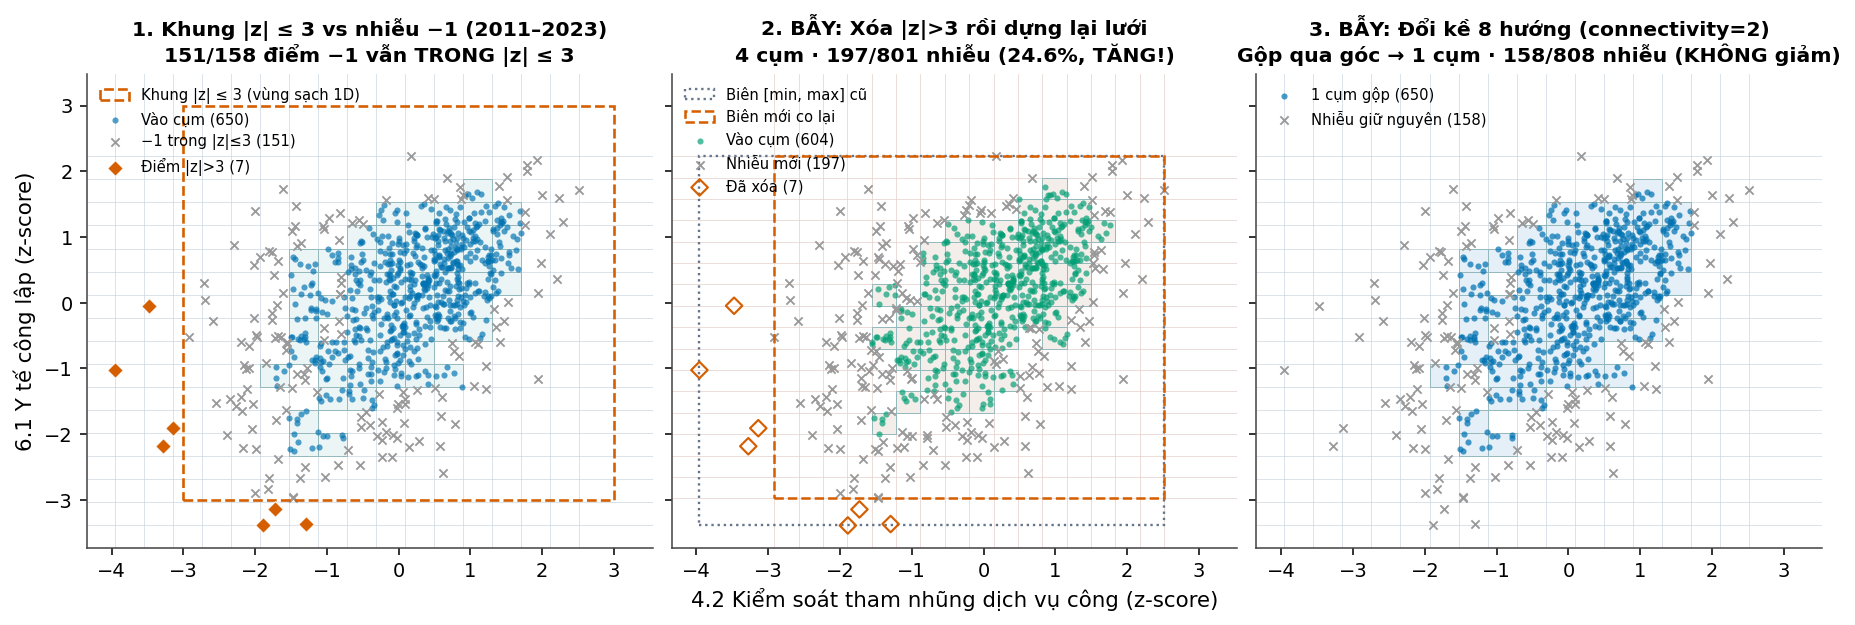

In [6]:
import copy
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scripts.common.fig_style import PALETTE, style_context

conn8_sting = copy.deepcopy(sting)
conn8_labels = conn8_sting.cluster(level=params["cluster_level"], connectivity=2)
conn8_noise = int((conn8_labels == -1).sum())

def _draw_sting_grid_ck(ax, m, *, grid_color="#CBD5E1", dense_fill="#EBF5F5"):
    res = m.factor ** m.cluster_level_
    b_lo, b_hi = m.bounds_min_, m.bounds_max_
    step = (b_hi - b_lo) / res
    for idx in m.label_of_:
        cell = m.cells_[m.cluster_level_][idx]
        ax.add_patch(Rectangle(cell.bounds_min, *(cell.bounds_max - cell.bounds_min),
                               facecolor=dense_fill, edgecolor="#94B8BC", linewidth=0.5, zorder=1))
    for i in range(res + 1):
        ax.axvline(b_lo[0] + i * step[0], color=grid_color, linewidth=0.35, zorder=0.5)
        ax.axhline(b_lo[1] + i * step[1], color=grid_color, linewidth=0.35, zorder=0.5)

_lo_t, _hi_t = sting.bounds_min_, sting.bounds_max_
_px_t, _py_t = (_hi_t[0] - _lo_t[0]) * 0.06, (_hi_t[1] - _lo_t[1]) * 0.06
with style_context():
    fig, axes = plt.subplots(1, 3, figsize=(13.0, 4.35), dpi=140, sharex=True, sharey=True, layout="constrained")
    _draw_sting_grid_ck(axes[0], sting)
    axes[0].add_patch(Rectangle((-3.0, -3.0), 6.0, 6.0, facecolor="none", edgecolor="#D55E00",
                                linestyle="--", linewidth=1.35, label="Khung |z| ≤ 3 (vùng sạch 1D)", zorder=4))
    _nm = train_labels == -1
    _sc = _nm & ~train_z_flag
    axes[0].scatter(train_scaled[~_nm, 0], train_scaled[~_nm, 1], s=10, color=PALETTE["blue"], alpha=0.68, linewidths=0,
                    label=f"Vào cụm ({int((~_nm).sum())})", zorder=2)
    axes[0].scatter(train_scaled[_sc, 0], train_scaled[_sc, 1], s=18, color=PALETTE["gray"], marker="x", linewidths=0.95,
                    label=f"−1 trong |z|≤3 ({train_sparse_no_flag})", zorder=3)
    axes[0].scatter(train_scaled[train_z_flag, 0], train_scaled[train_z_flag, 1], s=32, color="#D55E00", marker="D",
                    edgecolors="white", linewidths=0.5, label=f"Điểm |z|>3 ({int(train_z_flag.sum())})", zorder=5)
    axes[0].set_title(f"1. Khung |z| ≤ 3 vs nhiễu −1 (2011–2023)\n{train_sparse_no_flag}/{train_noise} điểm −1 vẫn TRONG |z| ≤ 3", fontsize=10.5)
    axes[0].set_ylabel("6.1 Y tế công lập (z-score)")
    axes[0].legend(loc="upper left", fontsize=7.6, framealpha=0.92)

    _draw_sting_grid_ck(axes[1], trimmed_sting, grid_color="#E2CFC9", dense_fill="#F3EEEA")
    axes[1].add_patch(Rectangle(_lo_t, *(_hi_t - _lo_t), facecolor="none", edgecolor="#64748B",
                                linestyle=":", linewidth=1.2, label="Biên [min, max] cũ", zorder=3))
    axes[1].add_patch(Rectangle(trimmed_sting.bounds_min_, *(trimmed_sting.bounds_max_ - trimmed_sting.bounds_min_),
                                facecolor="none", edgecolor="#D55E00", linestyle="--", linewidth=1.3, label="Biên mới co lại", zorder=4))
    _kept = train_scaled[~train_z_flag]
    _ta = trimmed_train_labels >= 0
    axes[1].scatter(_kept[_ta, 0], _kept[_ta, 1], s=10, color=PALETTE["green"], alpha=0.68, linewidths=0,
                    label=f"Vào cụm ({int(_ta.sum())})", zorder=2)
    axes[1].scatter(_kept[~_ta, 0], _kept[~_ta, 1], s=18, color=PALETTE["gray"], marker="x", linewidths=0.95,
                    label=f"Nhiễu mới ({trimmed_train_noise})", zorder=3)
    axes[1].scatter(train_scaled[train_z_flag, 0], train_scaled[train_z_flag, 1], s=36, facecolors="none", edgecolors="#D55E00",
                    marker="D", linewidths=1.1, label=f"Đã xóa ({int(train_z_flag.sum())})", zorder=5)
    axes[1].set_title(f"2. BẪY: Xóa |z|>3 rồi dựng lại lưới\n{trimmed_sting.n_clusters_} cụm · {trimmed_train_noise}/{len(trimmed_train_labels)} nhiễu ({trimmed_train_noise / len(trimmed_train_labels):.1%}, TĂNG!)", fontsize=10.5)
    axes[1].set_xlabel("4.2 Kiểm soát tham nhũng dịch vụ công (z-score)")
    axes[1].legend(loc="upper left", fontsize=7.6, framealpha=0.92)

    _draw_sting_grid_ck(axes[2], conn8_sting, dense_fill="#E4EFF7")
    _c8a = conn8_labels >= 0
    axes[2].scatter(train_scaled[_c8a, 0], train_scaled[_c8a, 1], s=10, color=PALETTE["blue"], alpha=0.72, linewidths=0,
                    label=f"1 cụm gộp ({int(_c8a.sum())})", zorder=2)
    axes[2].scatter(train_scaled[~_c8a, 0], train_scaled[~_c8a, 1], s=18, color=PALETTE["gray"], marker="x", linewidths=0.95,
                    label=f"Nhiễu giữ nguyên ({conn8_noise})", zorder=3)
    axes[2].set_title(f"3. BẪY: Đổi kề 8 hướng (connectivity=2)\nGộp qua góc → {conn8_sting.n_clusters_} cụm · {conn8_noise}/{len(conn8_labels)} nhiễu (KHÔNG giảm)", fontsize=10.5)
    axes[2].legend(loc="upper left", fontsize=7.6, framealpha=0.92)

    axes[0].set_xlim(min(_lo_t[0], -3.15) - _px_t, max(_hi_t[0], 3.15) + _px_t)
    axes[0].set_ylim(min(_lo_t[1], -3.15) - _py_t, max(_hi_t[1], 3.15) + _py_t)
    plt.show()

## 2. So sánh STING vs k-means vs DBSCAN (pooled 2011–2023)

Noise (−1) **được tách khỏi** silhouette/DB/CH (metric hình học tính trên điểm thuộc cụm).
k-means luôn gán hết điểm (ép k), STING không ép — đây là khác biệt phương pháp cần nói rõ.

In [7]:
metrics = pd.read_csv(ROOT / "results/metrics.csv")
show_md(metrics[metrics.scope == "pooled 2011-2023"].to_markdown(index=False))

| scope            | method         |   k |   noise_ratio |   silhouette |   davies_bouldin |   calinski_harabasz |   ari_vs_sting | note                                             |
|:-----------------|:---------------|----:|--------------:|-------------:|-----------------:|--------------------:|---------------:|:-------------------------------------------------|
| pooled 2011-2023 | STING (frozen) |   3 |         0.196 |        0.361 |            0.472 |                62   |        nan     | k=3: [629,16,5]; noise tách khỏi metric hình học |
| pooled 2011-2023 | k-means k=2    |   2 |         0     |        0.445 |            0.876 |               812.3 |          0.166 | tất cả điểm được gán cụm                         |
| pooled 2011-2023 | k-means k=3    |   3 |         0     |        0.336 |            1.05  |               665.7 |          0.139 | tất cả điểm được gán cụm                         |
| pooled 2011-2023 | k-means k=4    |   4 |         0     |        0.364 |            0.879 |               669.1 |          0.082 | tất cả điểm được gán cụm                         |
| pooled 2011-2023 | k-means k=5    |   5 |         0     |        0.334 |            0.945 |               647.9 |          0.07  | tất cả điểm được gán cụm                         |
| pooled 2011-2023 | DBSCAN eps=0.2 |   5 |         0.142 |        0.218 |            0.505 |                35.3 |          0.647 | nan                                              |
| pooled 2011-2023 | DBSCAN eps=0.4 |   1 |         0.027 |      nan     |          nan     |               nan   |          0.135 | metric n/a khi <2 cụm                            |
| pooled 2011-2023 | DBSCAN eps=0.6 |   1 |         0.009 |      nan     |          nan     |               nan   |          0.043 | metric n/a khi <2 cụm                            |
| pooled 2011-2023 | DBSCAN eps=0.8 |   1 |         0.002 |      nan     |          nan     |               nan   |          0.012 | metric n/a khi <2 cụm                            |
| pooled 2011-2023 | DBSCAN eps=1.0 |   1 |         0.001 |      nan     |          nan     |               nan   |          0.006 | metric n/a khi <2 cụm                            |

**Đọc bảng (trung thực):**
- Trên hai chỉ tiêu và cấu hình chính, STING cho một cụm 629 điểm và hai cụm nhỏ 16, 5 điểm; kết quả này không đại diện cho toàn bộ PAPI.
- ARI STING vs k-means thấp (0.07–0.17): hai phương pháp tạo các phân hoạch khác nhau trên tập đặc trưng đang xét.
- STING đồng thuận với DBSCAN(eps=0.2) hơn (ARI ≈ 0.65) — cùng họ mật độ.
- k-means cho silhouette cao hơn (0.445) nhưng **ép mọi điểm vào cụm**; STING có nhiễu 20% tách riêng.

## 3. STING theo từng năm

In [8]:
per_year = pd.read_csv(ROOT / "results/per_year.csv")
show_md(per_year.to_markdown(index=False))
print()
single_cluster_years = per_year["k"].eq(1).sum()
print(f"{single_cluster_years}/{len(per_year)} năm có một cụm với lưới 3 × 3 và min_count=3.")

|   year |   n |   k |   noise_ratio | cluster_sizes   |
|-------:|----:|----:|--------------:|:----------------|
|   2011 |  63 |   1 |         0.063 | [59]            |
|   2012 |  63 |   1 |         0     | [63]            |
|   2013 |  63 |   1 |         0.048 | [60]            |
|   2014 |  61 |   1 |         0.016 | [60]            |
|   2015 |  63 |   1 |         0.032 | [61]            |
|   2016 |  63 |   1 |         0.032 | [61]            |
|   2017 |  63 |   1 |         0.063 | [59]            |
|   2018 |  61 |   1 |         0.049 | [58]            |
|   2019 |  63 |   1 |         0.016 | [62]            |
|   2020 |  63 |   1 |         0.063 | [59]            |
|   2021 |  60 |   1 |         0.067 | [56]            |
|   2022 |  61 |   1 |         0.033 | [59]            |
|   2023 |  61 |   1 |         0     | [61]            |
|   2024 |  61 |   1 |         0.049 | [58]            |


14/14 năm có một cụm với lưới 3 × 3 và min_count=3.


## 4. Gán cụm năm 2024 và xem dịch chuyển theo thời gian

Dùng lưới học từ 2011–2023. Trên 61 tỉnh đủ hai chỉ tiêu năm 2024, có 48 tỉnh
vào cụm lớn và 13 tỉnh nhận nhãn nhiễu. Hai tỉnh thiếu chỉ tiêu được để trống.

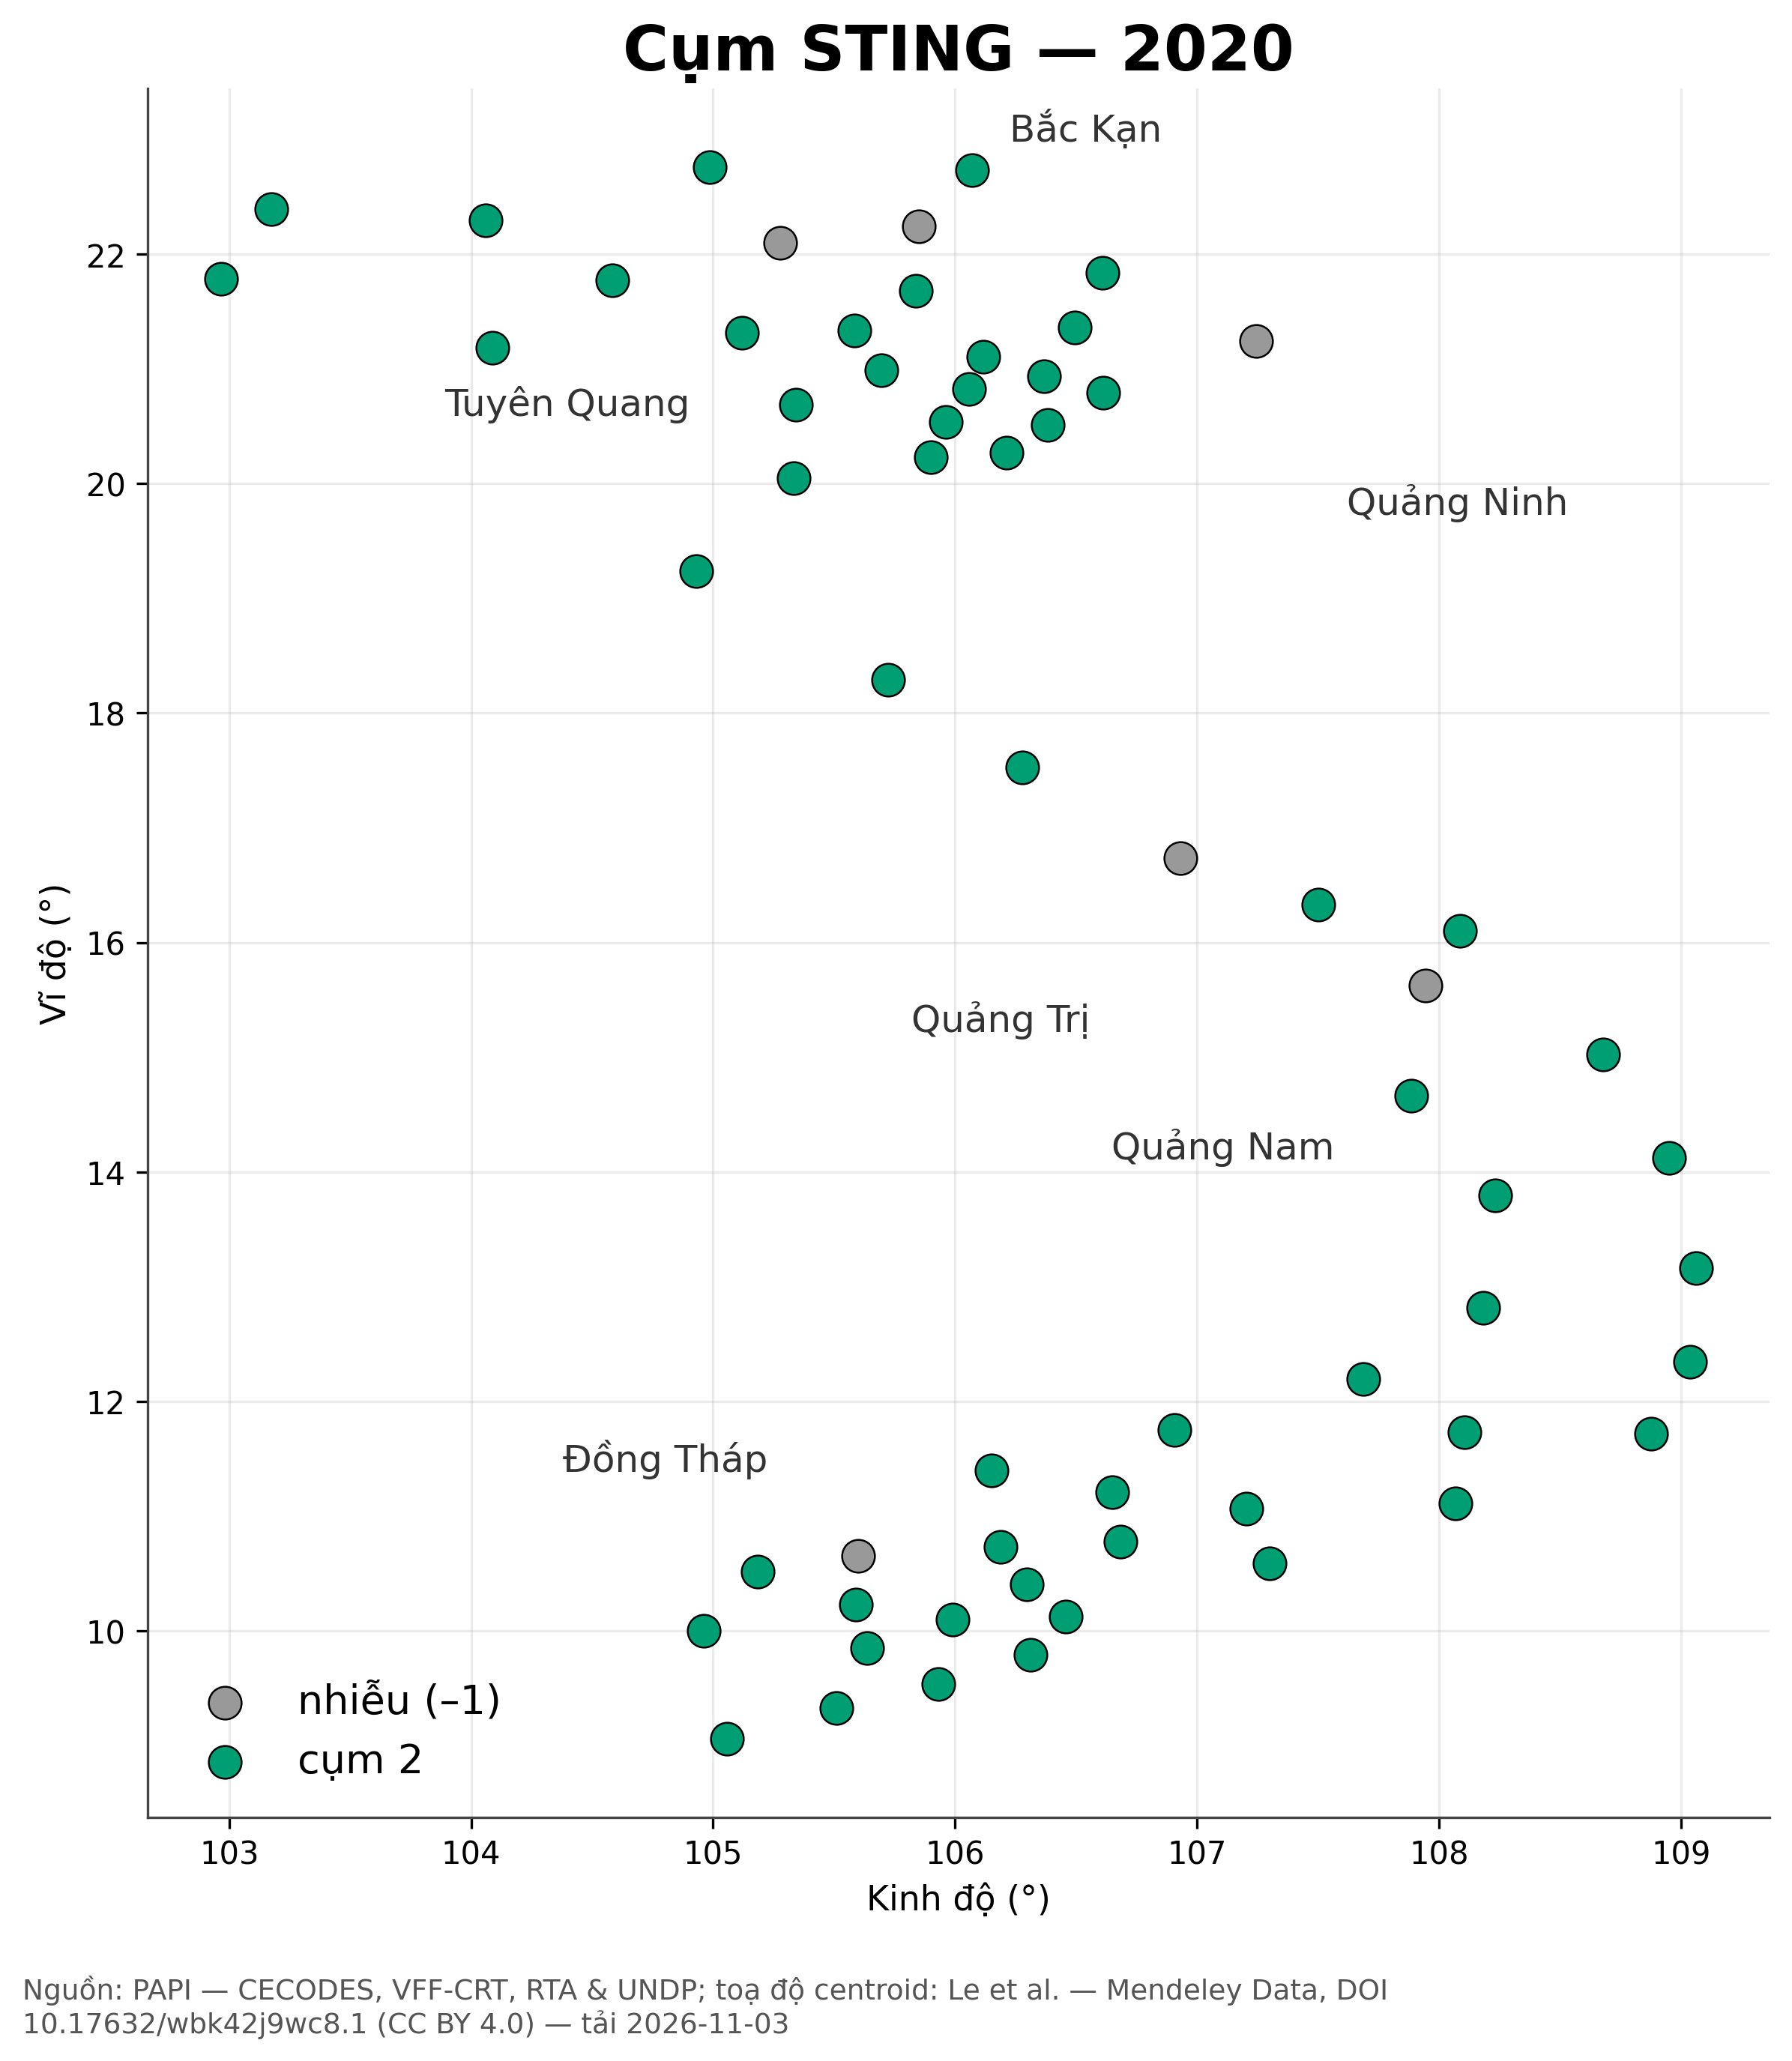

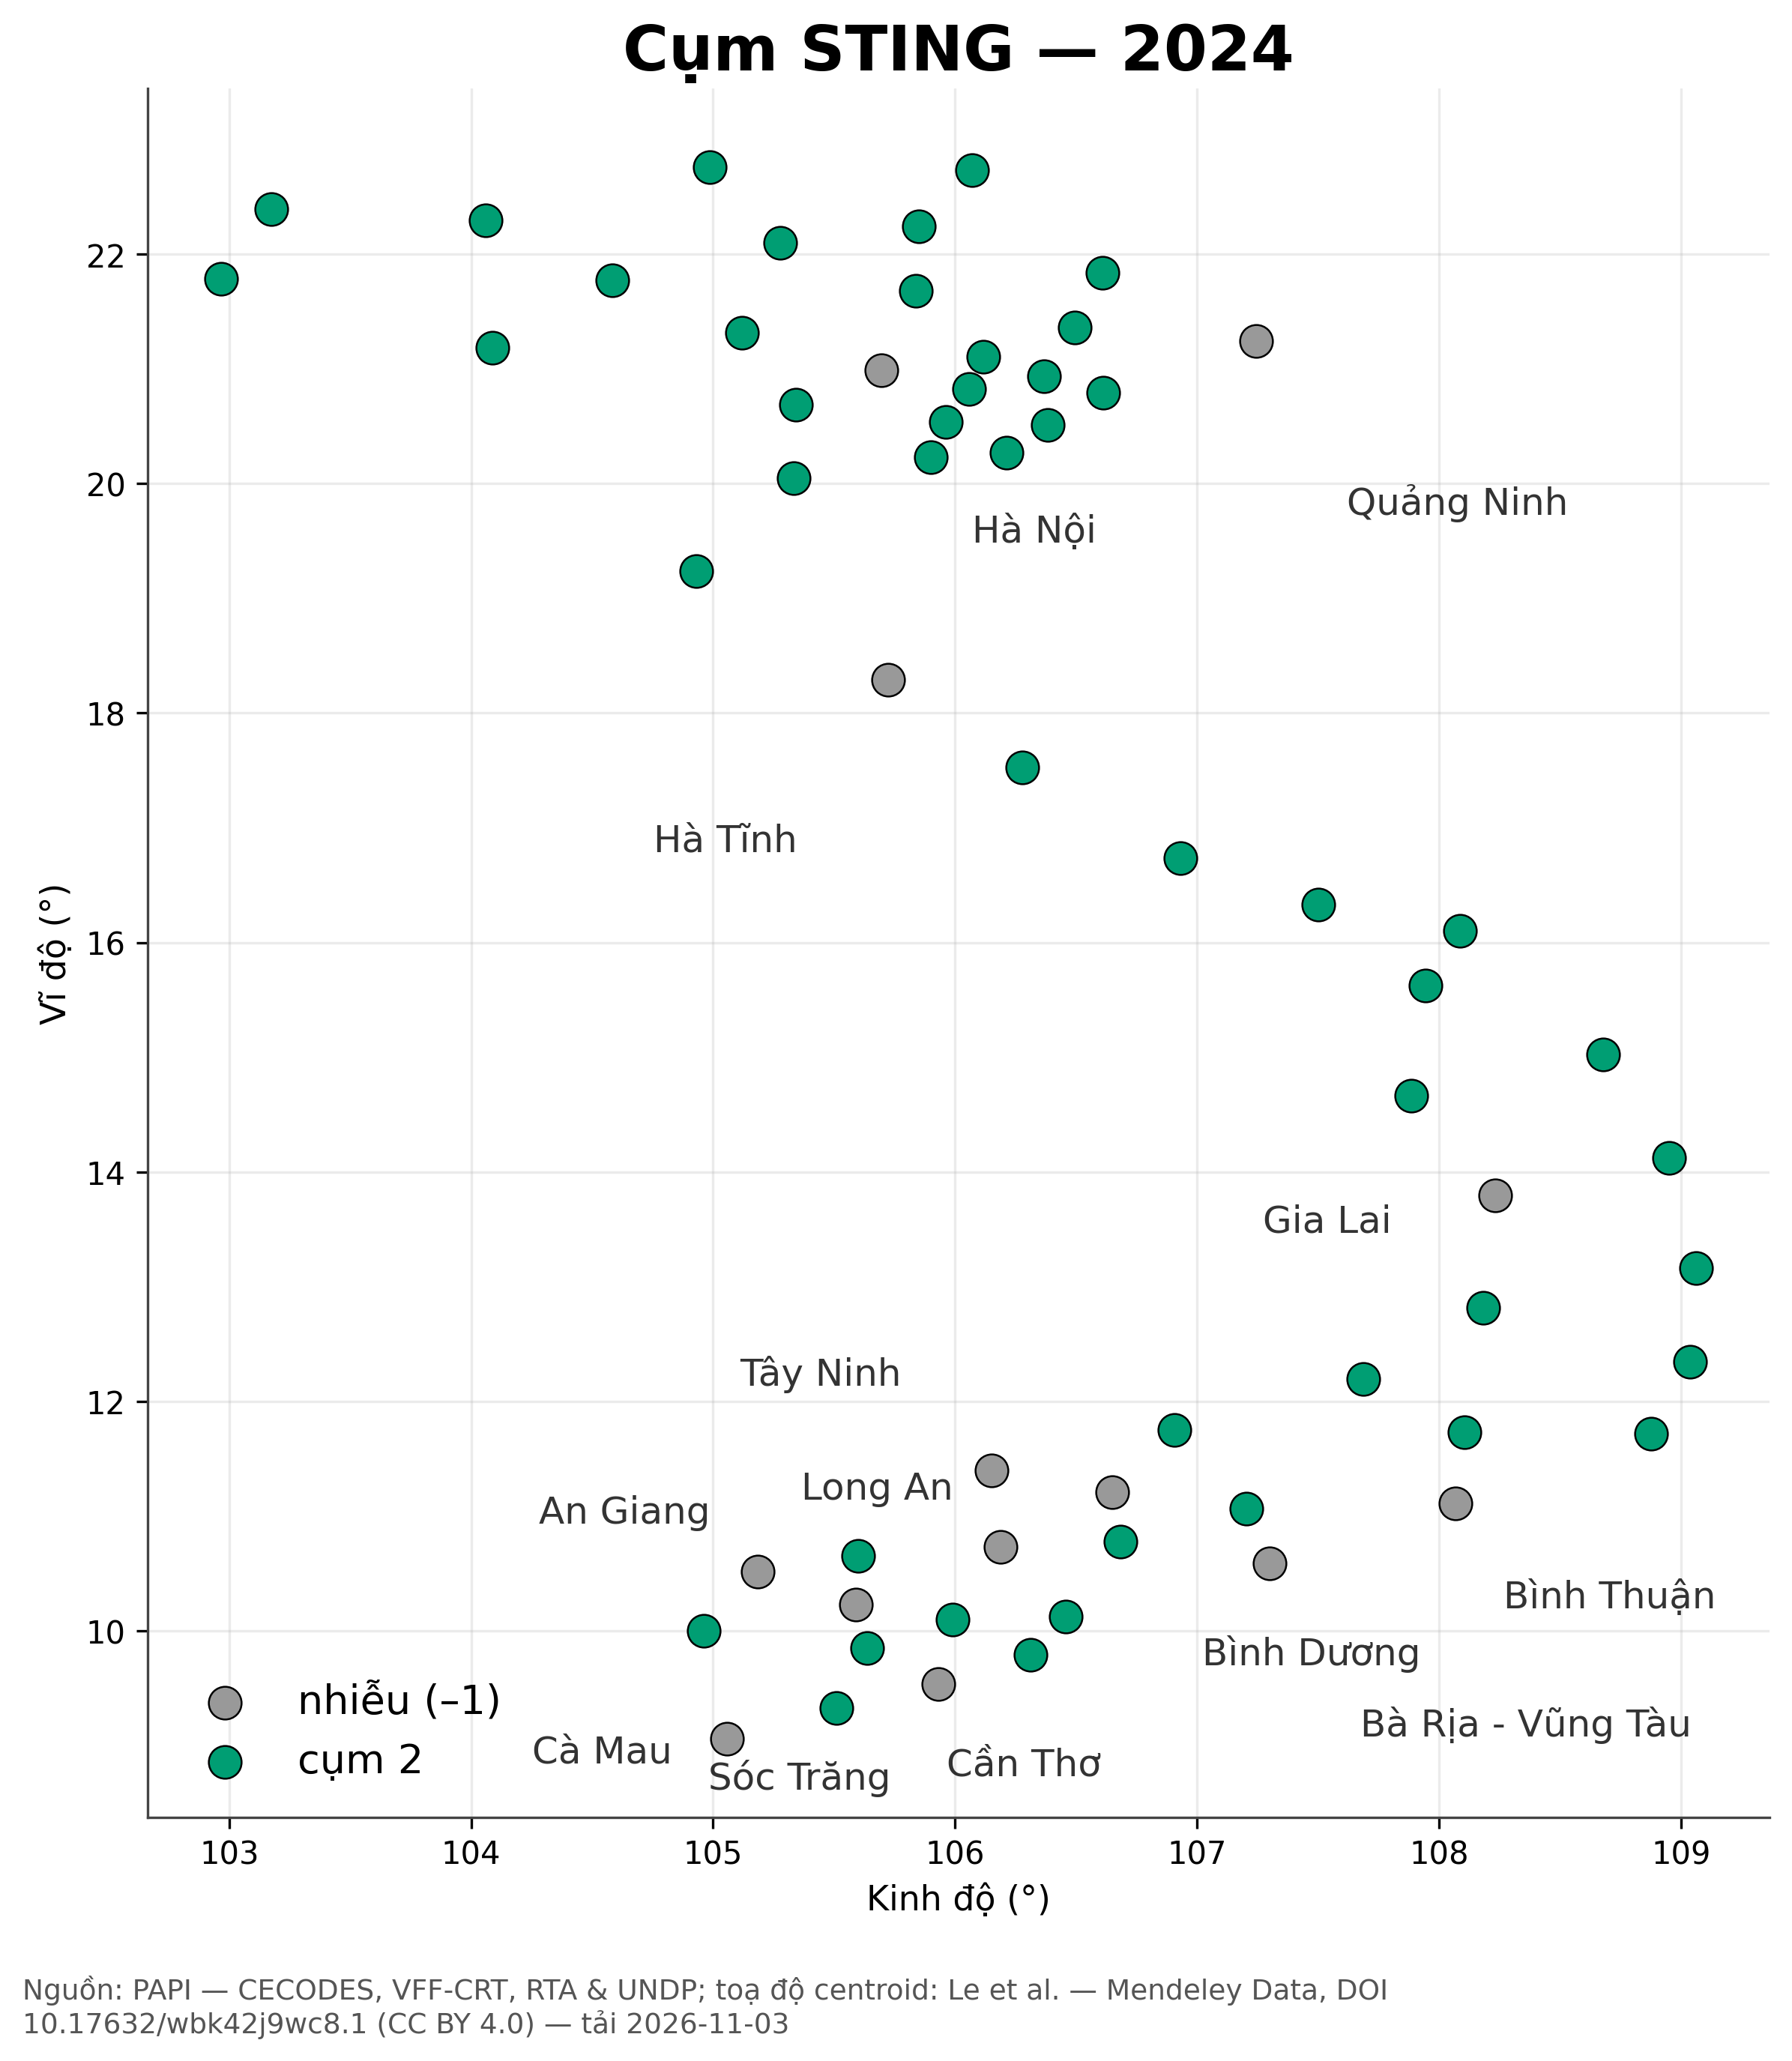

In [9]:
from IPython.display import Image, display
for year in (2020, 2024):
    display(Image(filename=str(ROOT / f"results/figs/map_{year}.png")))

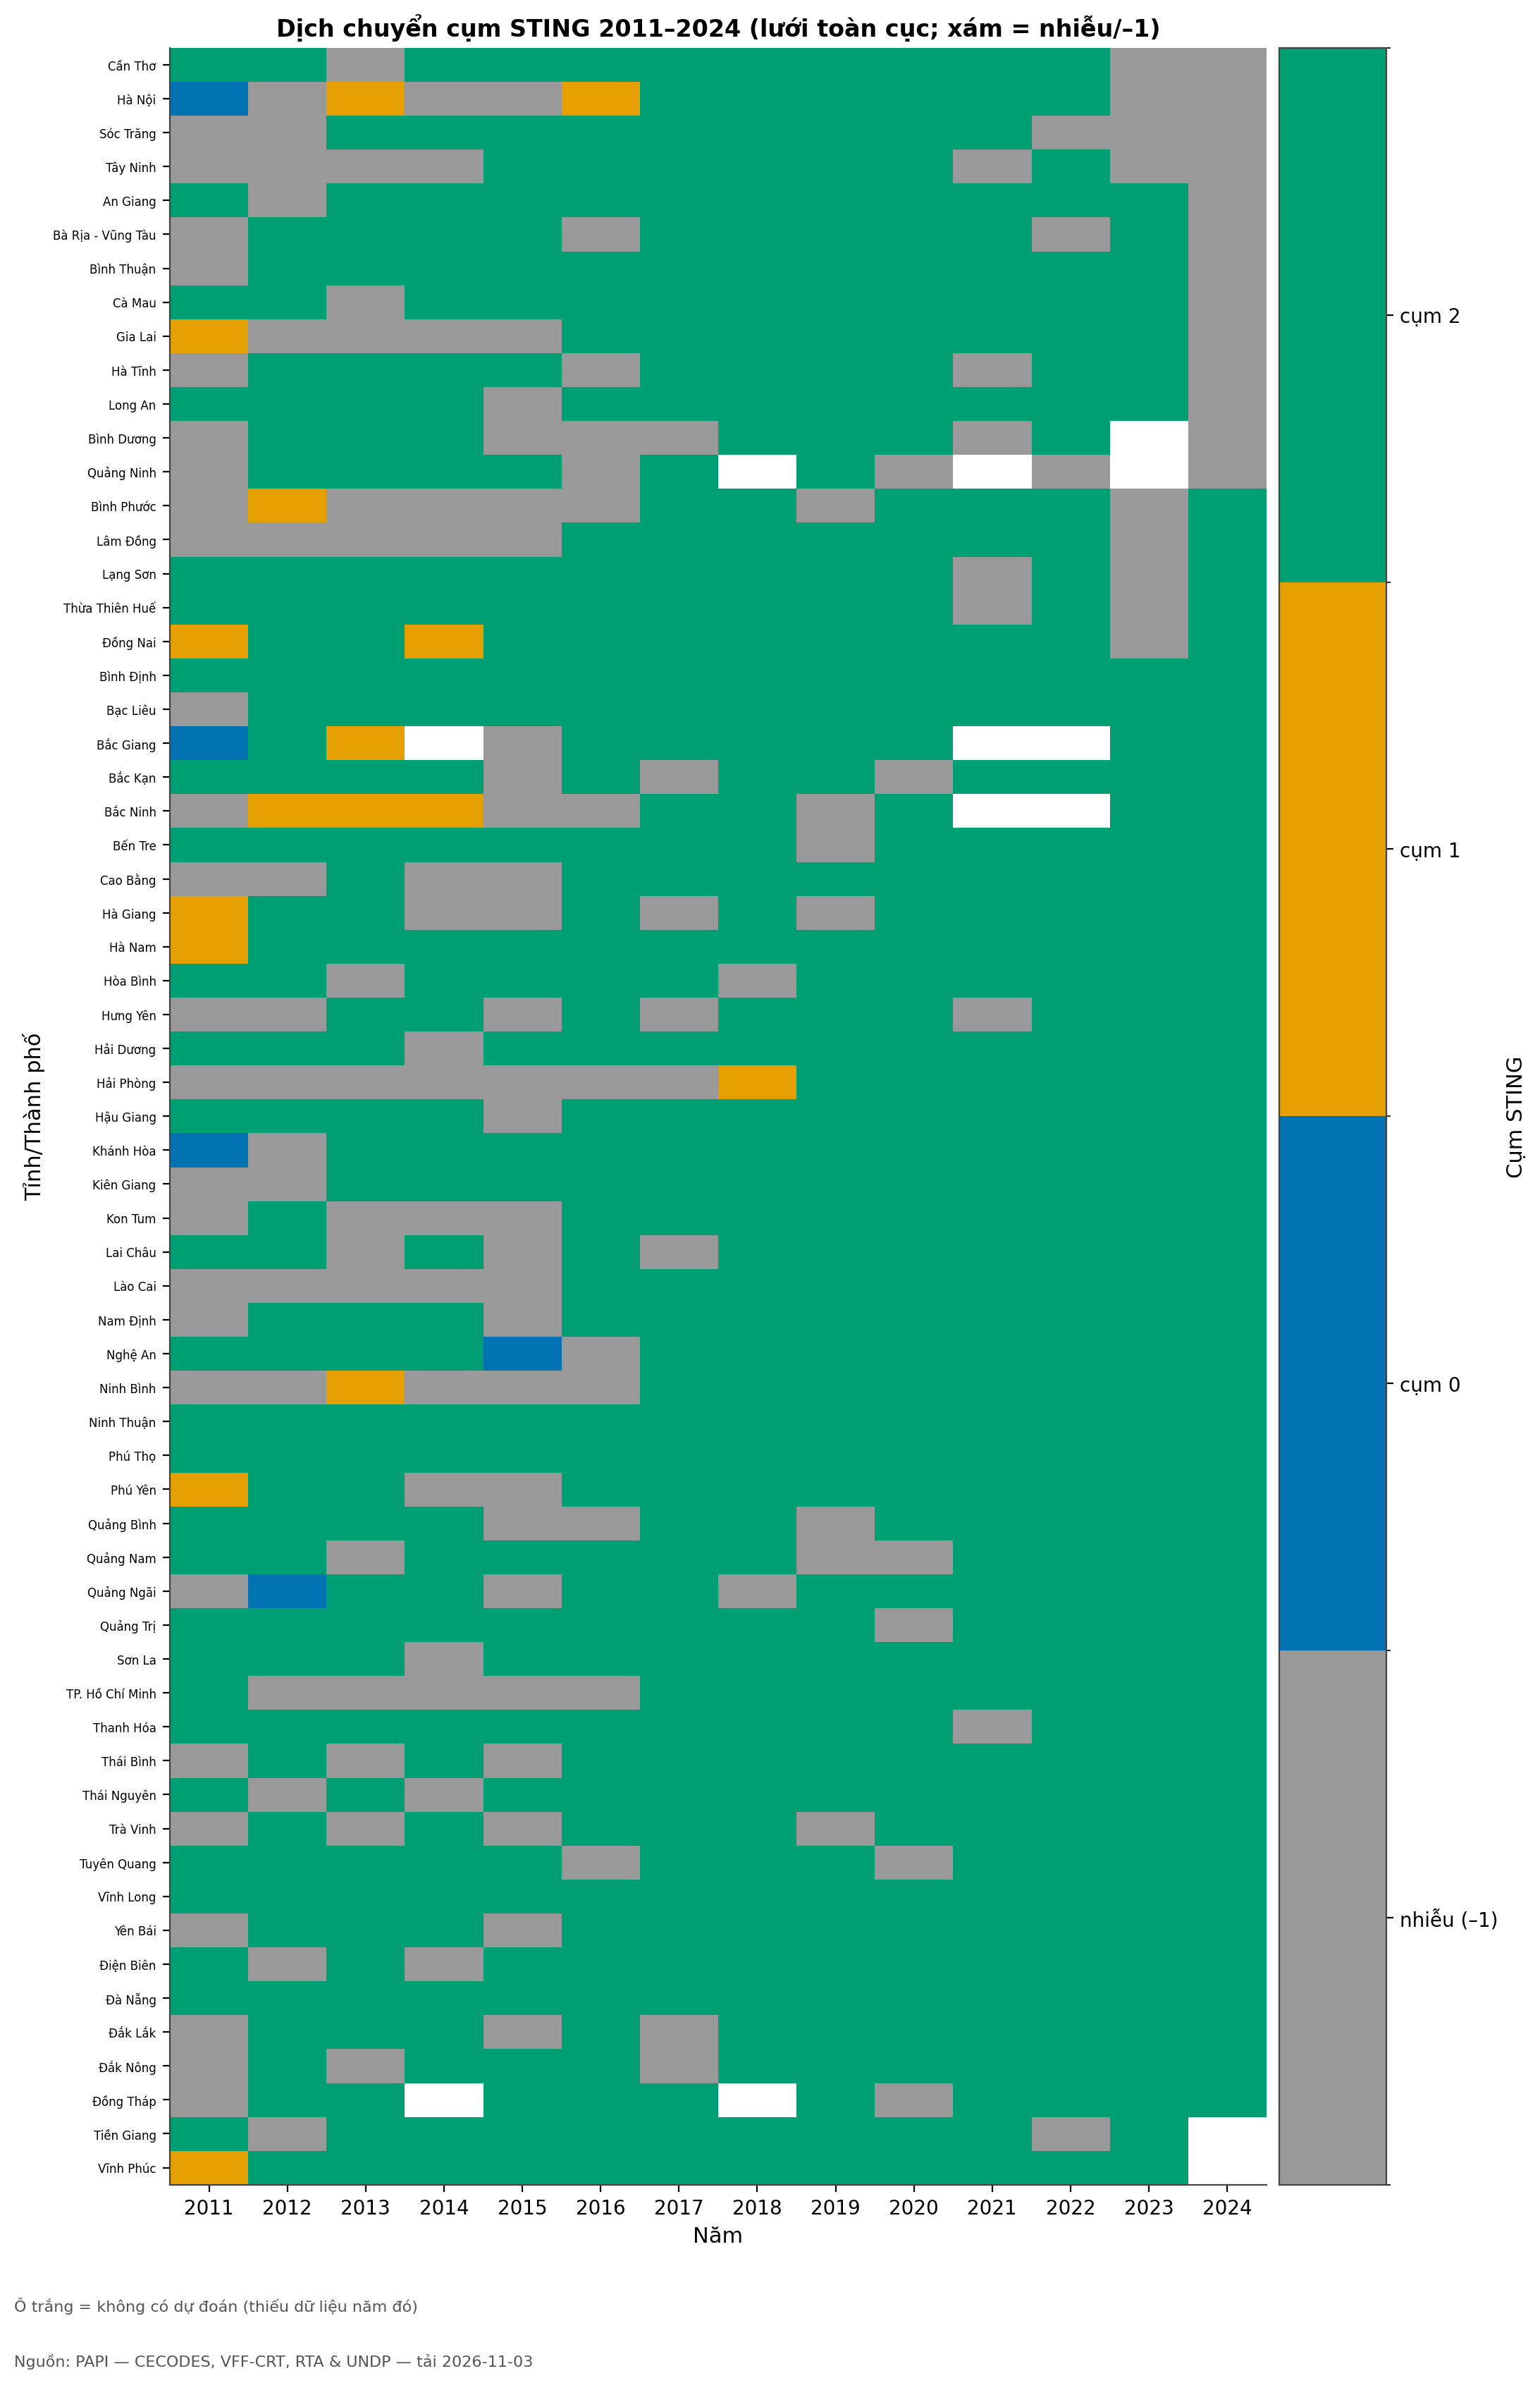

In [10]:
display(Image(filename=str(ROOT / "results/figs/evolution.png")))

**Chú thích evolution:** lưới TOÀN CỤC (không refit per-year) để nhãn có thể so sánh giữa các năm;
xám = nhiễu (−1); trắng = thiếu chỉ tiêu năm đó. Đọc được xu hướng: phần lớn tỉnh nằm trong cụm lớn
trong mọi năm; một số tỉnh vào/ra vùng ngoại vi theo thời gian.

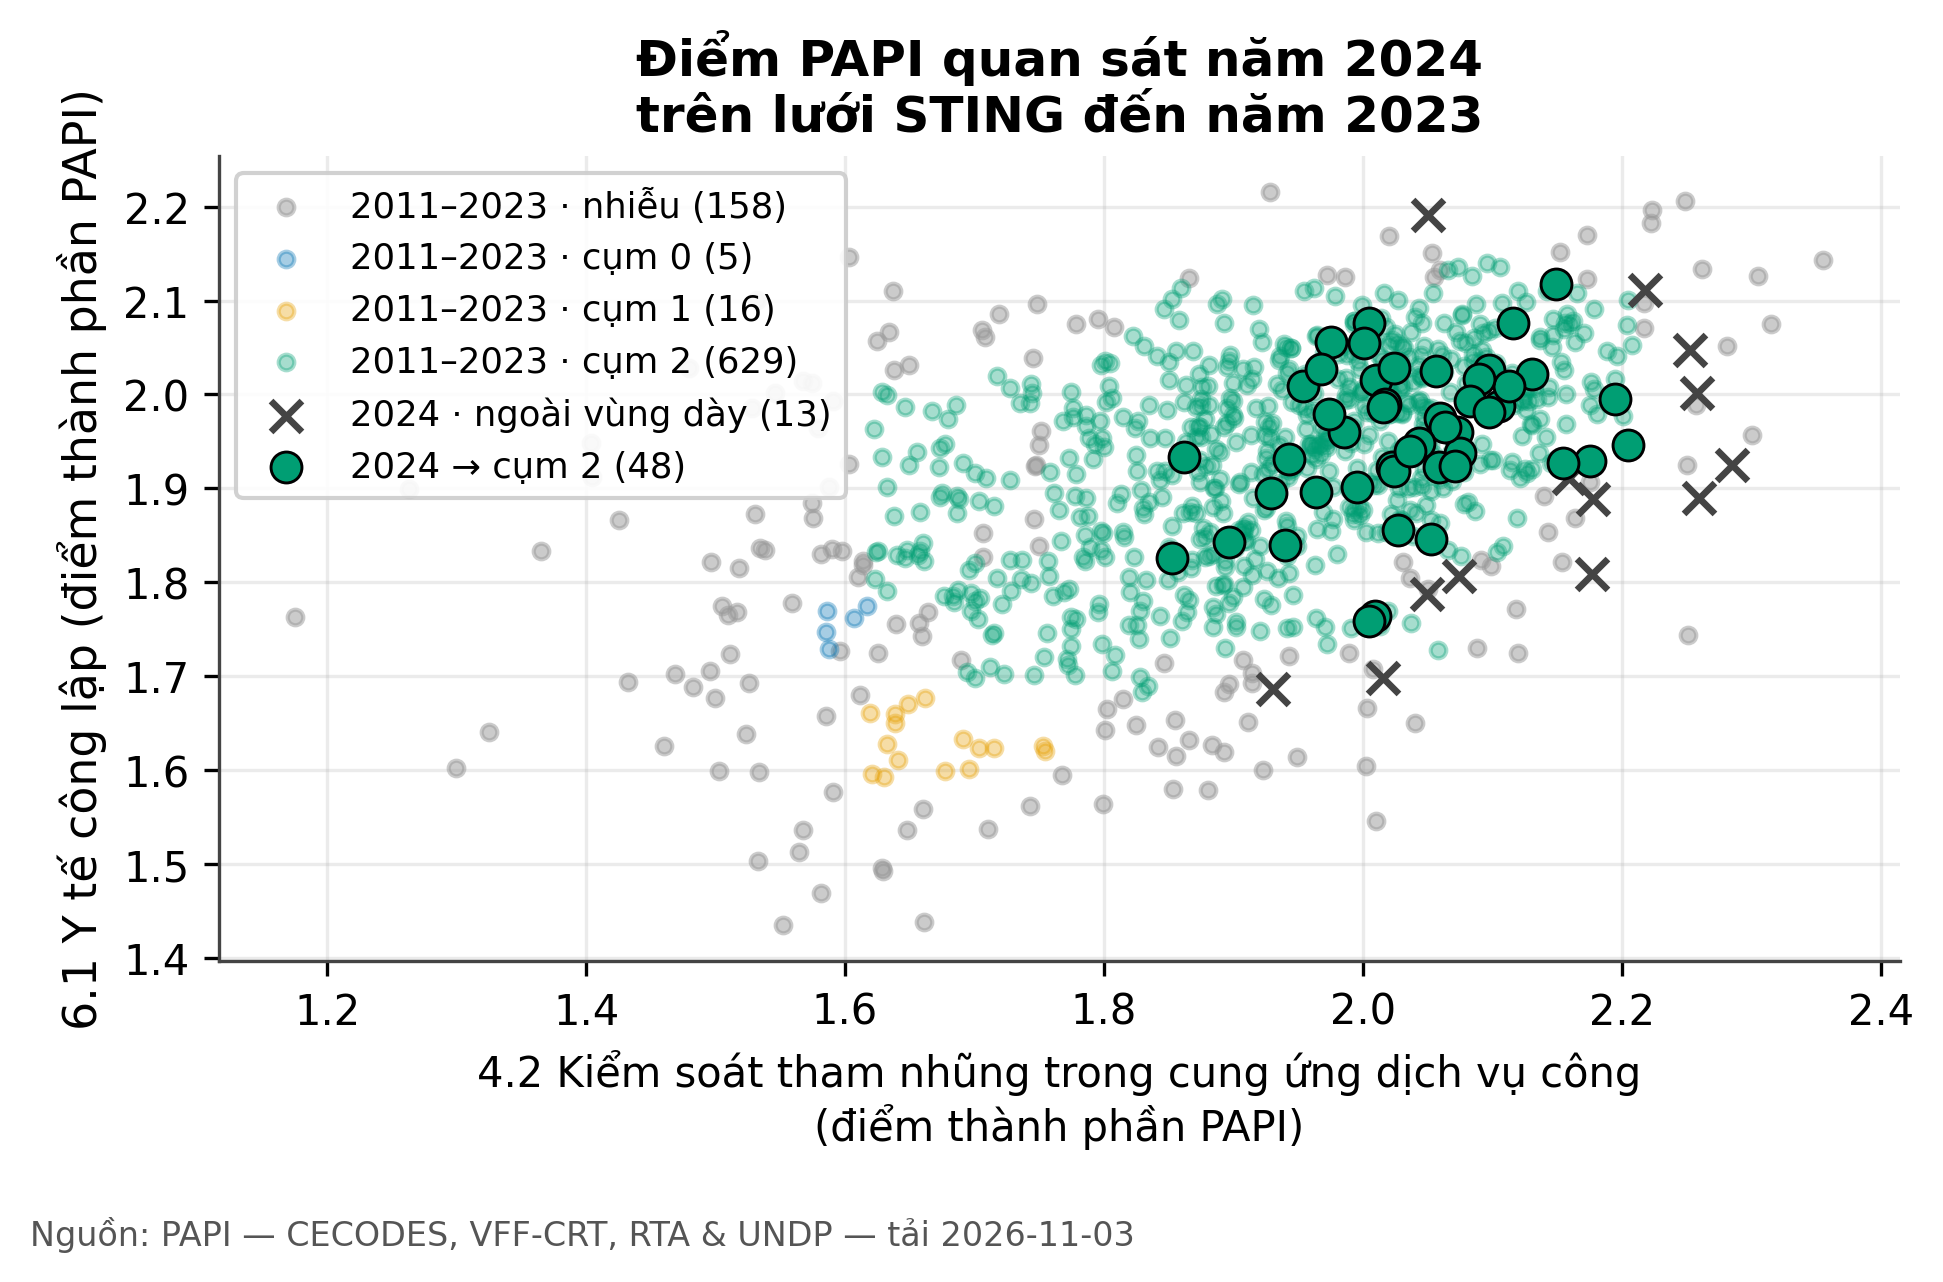

,Số tỉnh
Kết quả gán,
Thuộc cụm,48
Ô thưa,13
Thiếu chỉ tiêu,2


Cả 13/13 tỉnh ô thưa năm 2024 đều có |z| ≤ 3 trên lưới tham chiếu (|z| lớn nhất = 2.1299).


,Tỉnh/thành phố,Điểm 4.2,Điểm 6.1,|z| lớn nhất,Ô lưới,Số điểm tham chiếu,Lý do
0,Hà Nội,1.9308,1.6863,1.5792,"(10, 5)",3,Ô thưa
1,Quảng Ninh,2.2598,1.8891,1.9907,"(14, 9)",0,Ô thưa
2,Vĩnh Phúc,NaN,NaN,NaN,<NA>,<NA>,Thiếu chỉ tiêu
3,Hà Tĩnh,2.0502,2.1914,2.0571,"(11, 15)",1,Ô thưa
4,Bình Thuận,2.2182,2.1117,1.7625,"(14, 13)",2,Ô thưa
5,Gia Lai,2.0496,1.7875,0.8504,"(11, 7)",3,Ô thưa
6,Tây Ninh,2.2852,1.9245,2.1299,"(15, 10)",1,Ô thưa
7,Bình Dương,2.1768,1.8083,1.5351,"(13, 7)",1,Ô thưa
8,Bà Rịa - Vũng Tàu,2.2581,2.0017,1.9811,"(14, 11)",1,Ô thưa
9,Long An,2.0740,1.8069,0.9715,"(12, 7)",2,Ô thưa


Bảng 63 tỉnh kèm ô, số điểm tham chiếu và lý do gán nằm trong results/papi_observed_grid_2024.csv.


In [11]:
from scripts.common.papi_pred_common import GRID_ASSIGNMENT_LABELS, describe_grid_assignment

display(Image(filename=str(ROOT / "results/figs/predict_2024.png")))
observed_grid = describe_grid_assignment(panel.loc[panel.year.eq(2024)], features, scaler, sting)
status_counts = observed_grid.grid_status.value_counts().rename(index=GRID_ASSIGNMENT_LABELS)
display(status_counts.rename("Số tỉnh").rename_axis("Kết quả gán").to_frame())
review_2024 = observed_grid.loc[observed_grid.grid_status.ne("in_cluster")].copy()
valid_2024 = review_2024[features].notna().all(axis=1)
review_2024["max_abs_z"] = np.nan
review_2024.loc[valid_2024, "max_abs_z"] = np.abs(
    scaler.transform(review_2024.loc[valid_2024, features])
).max(axis=1)
sparse_2024 = review_2024.loc[review_2024.grid_status.eq("sparse_cell")]
assert (sparse_2024["max_abs_z"] <= 3).all()
print(f"Cả {len(sparse_2024)}/{len(sparse_2024)} tỉnh ô thưa năm 2024 đều có |z| ≤ 3 "
      f"trên lưới tham chiếu (|z| lớn nhất = {sparse_2024['max_abs_z'].max():.4f}).")
review_2024["grid_status"] = review_2024.grid_status.map(GRID_ASSIGNMENT_LABELS)
display(review_2024[["province_vi", *features, "max_abs_z", "grid_cell", "reference_count", "grid_status"]].rename(columns={
    "province_vi": "Tỉnh/thành phố", "sd_4_2": "Điểm 4.2", "sd_6_1": "Điểm 6.1",
    "max_abs_z": "|z| lớn nhất", "grid_cell": "Ô lưới",
    "reference_count": "Số điểm tham chiếu", "grid_status": "Lý do",
}).round(4).reset_index(drop=True))
print("Bảng 63 tỉnh kèm ô, số điểm tham chiếu và lý do gán nằm trong results/papi_observed_grid_2024.csv.")

## 5. Kết luận

- STING gom các ô dày liên thông. Trên PAPI 2011–2023, cụm lớn có 629 điểm,
  hai cụm nhỏ có 16 và 5 điểm, với 19,6% nhiễu.
- Các cấu hình lưới làm thay đổi số cụm và tỷ lệ nhiễu. Kết quả mô tả hai chỉ
  tiêu được chọn, trong phạm vi lưới và thời gian đã kiểm tra.
- Khi đọc silhouette, xem cùng tỉ lệ nhiễu. Các phương pháp có thể được đánh giá
  trên các tập điểm khác nhau.

**Nguồn:** Wang, Yang & Muntz (VLDB 1997), PAPI (CECODES/VFF-CRT/RTA/UNDP),
Le et al. (Mendeley DOI 10.17632/wbk42j9wc8.1) và Open Development Vietnam.

## Phụ lục A. Kiểm tra bổ sung trên nhiều chỉ tiêu

- **Thử PCA:** ≥2 thành phần trên d1–d6 toàn panel (trong-năm z để khử bước nhảy).
  Kết quả: 2 PC đầu chỉ giữ 63.2% phương sai; STING trên không gian PCA → k=1 → **không nhận diện cấu trúc** (trung thực).
- **Nhánh 8 chiều OFAT** (chỉ 2018–2024, 430 điểm — lưới 8-D quá thưa; đổi MỘT tham số mỗi lần từ gốc `L=3 f=2 mc=10 lv=1 (gốc OFAT)`):
  gốc → k=3, noise=60.5% (silhouette 0.297);
  chỉ f=3 → k=1, noise=91.9%; chỉ mc=2 → k=2, noise=10.9% (verdict "có cấu trúc" — silhouette -0.089, tách yếu); chỉ lv=2 → k=0, noise=100%.
  → ablation chỉ ra **kết quả nhạy với factor và cluster_level**; nhánh mc=2 tuy verdict "có cấu trúc" nhưng silhouette âm nên không phải cụm dùng được.
- Kết luận: không tìm thấy cụm ổn định khi mở rộng chiều; cluster hóa hiện hữu chỉ có ý nghĩa ở không gian 2D cục bộ.
  Đây là **kết quả âm tính đáng báo cáo** — các cấu hình đã thử chưa cho bằng chứng phân tách mạnh; không suy ra mọi tập đặc trưng hay cấu hình khác đều như vậy.

In [12]:
rob = pd.read_csv(ROOT / "results/robustness.csv")
show_md(rob.to_markdown(index=False))

| branch                                                                   |   n |   explained_var_total |   k |   noise_ratio |   silhouette |        db |        ch |   ari_vs_2d | verdict         |
|:-------------------------------------------------------------------------|----:|----------------------:|----:|--------------:|-------------:|----------:|----------:|------------:|:----------------|
| PCA(2) d1–d6, within-year z, pooled                                      | 869 |                 0.632 |   1 |         0.062 |  nan         | nan       | nan       |       0.008 | không nhận diện |
| 8 chiều 2018–2024, within-year z, L=3 f=2 mc=10 lv=1 (gốc OFAT)          | 430 |               nan     |   3 |         0.605 |    0.297194  |   1.13107 |  83.8316  |     nan     | không nhận diện |
| 8 chiều 2018–2024, within-year z, OFAT f=3 (còn như gốc: L=3 mc=10 lv=1) | 430 |               nan     |   1 |         0.919 |  nan         | nan       | nan       |     nan     | không nhận diện |
| 8 chiều 2018–2024, within-year z, OFAT mc=2 (còn như gốc: L=3 f=2 lv=1)  | 430 |               nan     |   2 |         0.109 |   -0.0886574 |   1.49983 |   1.14207 |     nan     | có cấu trúc     |
| 8 chiều 2018–2024, within-year z, OFAT lv=2 (còn như gốc: L=3 f=2 mc=10) | 430 |               nan     |   0 |         1     |  nan         | nan       | nan       |     nan     | không nhận diện |

## Phụ lục B. Mô hình giám sát bổ trợ

Ridge và Random Forest minh họa dự báo chỉ tiêu y tế năm sau. Chọn bằng CV theo
thời gian và đánh giá trên 2023→2024. Bài phân loại dùng nhãn do STING sinh.
Kết quả phân loại đo mức khớp với nhãn lưới trong một holdout.

In [13]:
sup = pd.read_csv(ROOT / "results/supervised_metrics.csv")
show_md(sup.to_markdown(index=False))

| task           | model                               | metric_cv                             |   value_cv |   holdout_mae |   holdout_rmse |   holdout_r2 |   holdout_acc |   holdout_macro_f1 |
|:---------------|:------------------------------------|:--------------------------------------|-----------:|--------------:|---------------:|-------------:|--------------:|-------------------:|
| regression     | carry-forward (giữ giá trị năm nay) | r2 (expanding origin 2017–2022)       |      0.145 |        0.0683 |         0.0875 |        0.198 |       nan     |            nan     |
| regression     | trung bình train                    | r2 (expanding origin 2017–2022)       |     -0.77  |        0.0814 |         0.1027 |       -0.105 |       nan     |            nan     |
| regression     | ridge                               | r2 (expanding origin 2017–2022)       |      0.265 |        0.064  |         0.0769 |        0.381 |       nan     |            nan     |
| regression     | random forest                       | r2 (expanding origin 2017–2022)       |      0.197 |        0.0616 |         0.0742 |        0.423 |       nan     |            nan     |
| classification | majority (lớp đa số)                | f1_macro (expanding origin 2017–2022) |      0.228 |      nan      |       nan      |      nan     |         0.186 |              0.157 |
| classification | logistic regression                 | f1_macro (expanding origin 2017–2022) |      0.434 |      nan      |       nan      |      nan     |         0.644 |              0.541 |
| classification | random forest                       | f1_macro (expanding origin 2017–2022) |      0.397 |      nan      |       nan      |      nan     |         0.678 |              0.6   |

In [14]:
import joblib
import sys
sys.path.insert(0, str(ROOT))
from scripts.common.papi_pred_common import REGRESSION_FEATURES
from scripts.supervised.predict_supervised import build_regression_pairs, expanding_origin_folds

print("8 regression features:", REGRESSION_FEATURES)
regression_pairs = build_regression_pairs(panel)
training_origins = regression_pairs.loc[
    regression_pairs.year_t < 2023, "year_t"
].to_numpy()
print("Regression folds use training origins only (year_t < 2023).")
folds = expanding_origin_folds(training_origins, first_validation_origin=2017)
for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):
    print(
        f"Fold {fold_number}: max train origin={training_origins[train_idx].max()}, "
        f"validation origin={training_origins[val_idx][0]}"
    )

regression_metrics = pd.read_csv(ROOT / "results/supervised_metrics.csv")
regression_models = regression_metrics[
    (regression_metrics.task == "regression")
    & ~regression_metrics.model.isin(
        ["carry-forward (giữ giá trị năm nay)", "trung bình train"]
    )
].dropna(subset=["value_cv"])
chosen = regression_models.loc[regression_models.value_cv.idxmax()]
print(f"CV-selected regression model: {chosen.model} (R²={chosen.value_cv:.3f})")

print("Loading ../models/sup_ridge.joblib")
ridge = joblib.load(ROOT / "models/sup_ridge.joblib")
probe = np.array([[1.5, 2.6, 2.0, 2.1, 1.9, 1.7, 1.9, 1.8]])
print("Fixed 8-feature probe:", probe.tolist()[0])
print("Ridge prediction:", ridge.predict(probe).tolist())
from sklearn.metrics import mean_absolute_error
holdout = regression_pairs[regression_pairs.year_t == 2023]
ridge_mae = mean_absolute_error(holdout.y, ridge.predict(holdout[REGRESSION_FEATURES].to_numpy()))
carry_mae = mean_absolute_error(holdout.y, holdout["carry"])
ridge_row = regression_metrics[(regression_metrics.task == "regression") & (regression_metrics.model == "ridge")].iloc[0]
assert abs(ridge_mae - ridge_row.holdout_mae) < 1e-5
print(f"Ridge holdout recalculated: n={len(holdout)}, MAE={ridge_mae:.4f}; carry-forward={carry_mae:.4f}")

8 regression features: ['sd_1_3', 'sd_1_4', 'sd_4_1', 'sd_4_2', 'sd_4_3', 'sd_4_4', 'sd_6_1', 'sd_6_3']
Regression folds use training origins only (year_t < 2023).
Fold 1: max train origin=2016, validation origin=2017
Fold 2: max train origin=2017, validation origin=2018
Fold 3: max train origin=2018, validation origin=2019
Fold 4: max train origin=2019, validation origin=2020
Fold 5: max train origin=2020, validation origin=2021
Fold 6: max train origin=2021, validation origin=2022
CV-selected regression model: ridge (R²=0.265)
Loading ../models/sup_ridge.joblib
Fixed 8-feature probe: [1.5, 2.6, 2.0, 2.1, 1.9, 1.7, 1.9, 1.8]
Ridge prediction: [1.9682530855137745]
Ridge holdout recalculated: n=59, MAE=0.0640; carry-forward=0.0683


Day 6 Logistic holdout 2023→2024 (59 tỉnh): BCE = 0.7059 | Acc = 0.644 | Macro-F1 = 0.541.


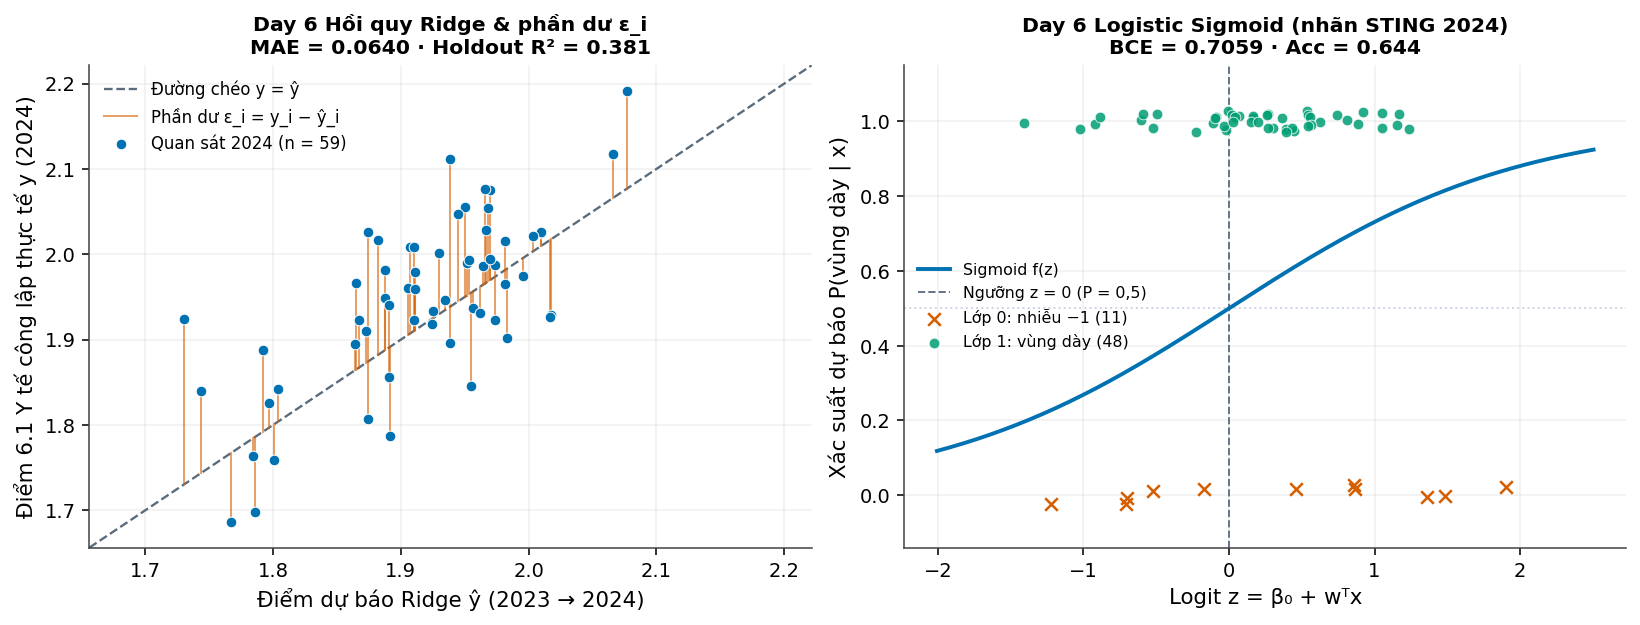

In [15]:
from sklearn.metrics import accuracy_score, f1_score, log_loss, r2_score
from scripts.supervised.predict_supervised import build_classification_pairs

y_true_reg = holdout.y.to_numpy()
y_pred_ridge = ridge.predict(holdout[REGRESSION_FEATURES].to_numpy())
ridge_r2 = r2_score(y_true_reg, y_pred_ridge)

clf_model = joblib.load(ROOT / "models/sup_classifier.joblib")
clf_pairs = build_classification_pairs(panel, features, params)
clf_hold = clf_pairs[clf_pairs.year_t == 2023]
Xc_te = clf_hold[REGRESSION_FEATURES].to_numpy()
yc_te = clf_hold["y"].to_numpy()
probs_te = clf_model.predict_proba(Xc_te)[:, 1]
logits_te = clf_model.decision_function(Xc_te)
preds_te = clf_model.predict(Xc_te)
bce_loss = log_loss(yc_te, probs_te)
clf_acc = accuracy_score(yc_te, preds_te)
clf_mf1 = f1_score(yc_te, preds_te, average="macro", labels=[0, 1], zero_division=0)
print(f"Day 6 Logistic holdout 2023→2024 ({len(yc_te)} tỉnh): BCE = {bce_loss:.4f} | Acc = {clf_acc:.3f} | Macro-F1 = {clf_mf1:.3f}.")

with style_context():
    fig, (ax_reg, ax_log) = plt.subplots(1, 2, figsize=(11.6, 4.35), dpi=140, layout="constrained")
    lo_r = float(min(y_true_reg.min(), y_pred_ridge.min())) - 0.03
    hi_r = float(max(y_true_reg.max(), y_pred_ridge.max())) + 0.03
    ax_reg.plot([lo_r, hi_r], [lo_r, hi_r], "--", color="#5A6B7C", lw=1.2, label="Đường chéo y = ŷ", zorder=1)
    for idx_i, (yt, yp) in enumerate(zip(y_true_reg, y_pred_ridge, strict=True)):
        ax_reg.plot([yp, yp], [yp, yt], "-", color="#D55E00", alpha=0.58, lw=1.05,
                    label="Phần dư ε_i = y_i − ŷ_i" if idx_i == 0 else None, zorder=2)
    ax_reg.scatter(y_pred_ridge, y_true_reg, s=30, color=PALETTE["blue"], edgecolors="white", linewidths=0.5,
                   label="Quan sát 2024 (n = 59)", zorder=3)
    ax_reg.set_xlim(lo_r, hi_r)
    ax_reg.set_ylim(lo_r, hi_r)
    ax_reg.set_xlabel("Điểm dự báo Ridge ŷ (2023 → 2024)")
    ax_reg.set_ylabel("Điểm 6.1 Y tế công lập thực tế y (2024)")
    ax_reg.set_title(f"Day 6 Hồi quy Ridge & phần dư ε_i\nMAE = {ridge_mae:.4f} · Holdout R² = {ridge_r2:.3f}", fontsize=10.5)
    ax_reg.grid(alpha=0.18)
    ax_reg.legend(loc="upper left", fontsize=8.5, framealpha=0.92)

    z_grid = np.linspace(float(logits_te.min()) - 0.6, float(logits_te.max()) + 0.6, 200)
    ax_log.plot(z_grid, 1.0 / (1.0 + np.exp(-z_grid)), "-", color=PALETTE["blue"], lw=2.0, label="Sigmoid f(z)", zorder=2)
    ax_log.axvline(0.0, color="#64748B", linestyle="--", lw=1.0, label="Ngưỡng z = 0 (P = 0,5)", zorder=1)
    ax_log.axhline(0.5, color="#CBD5E1", linestyle=":", lw=1.0, zorder=1)
    m0, m1 = yc_te == 0, yc_te == 1
    rng_j = np.random.default_rng(42)
    ax_log.scatter(logits_te[m0], rng_j.uniform(-0.03, 0.03, size=int(m0.sum())), s=42, color="#D55E00", marker="x", lw=1.3,
                   label=f"Lớp 0: nhiễu −1 ({int(m0.sum())})", zorder=4)
    ax_log.scatter(logits_te[m1], 1.0 + rng_j.uniform(-0.03, 0.03, size=int(m1.sum())), s=30, color=PALETTE["green"], alpha=0.85,
                   edgecolors="white", lw=0.45, label=f"Lớp 1: vùng dày ({int(m1.sum())})", zorder=4)
    ax_log.set_ylim(-0.14, 1.15)
    ax_log.set_xlabel("Logit z = β₀ + wᵀx")
    ax_log.set_ylabel("Xác suất dự báo P(vùng dày | x)")
    ax_log.set_title(f"Day 6 Logistic Sigmoid (nhãn STING 2024)\nBCE = {bce_loss:.4f} · Acc = {clf_acc:.3f}", fontsize=10.5)
    ax_log.grid(alpha=0.18)
    ax_log.legend(loc="center left", fontsize=8.2, framealpha=0.92)
    plt.show()

## Phụ lục C. Đối chiếu PCI và nghèo GSO

- Bảng đối chiếu PCI có trong `results/external_validation.md`.
- Nguồn GSO: tỷ lệ hộ nghèo cấp tỉnh **GSO pxweb V14.47** (thống kê chính thức,
  tách khỏi PAPI); 2017–2019 lấy từ Niên giám Thống kê 2020/2021.
  KHÔNG vào feature, KHÔNG nội suy ô thiếu (TP.HCM 2016 thiếu phía nguồn).
- Mọi số dưới đây **đọc trực tiếp từ `results/poverty_validation.csv`** (sinh bởi `scripts/analysis/poverty_validation.py`) — không hardcode.
- Nên đọc hai kiểm định cùng nhau: gộp thô (nhiễm hiệu ứng năm — chuẩn nghèo đổi theo giai đoạn,
  median nghèo giảm sâu xuyên giai đoạn) và đã-trừ-median-trong-năm (tách hiệu ứng năm).

| section                 | group      |   year |   n |   mean |   median |   std |   min |   max |   note |
|:------------------------|:-----------|-------:|----:|-------:|---------:|------:|------:|------:|-------:|
| poverty_pooled_raw      | nhiễu (–1) |    nan | 144 |  9.872 |     6.6  | 9.937 |   0   |  42.3 |    nan |
| poverty_pooled_raw      | cụm 0      |    nan |   2 | 14.95  |    14.95 | 3.748 |  12.3 |  17.6 |    nan |
| poverty_pooled_raw      | cụm 1      |    nan |  10 |  4.55  |     3.25 | 3.641 |   1.2 |  12.1 |    nan |
| poverty_pooled_raw      | cụm 2      |    nan | 649 |  9.008 |     6.2  | 8.729 |   0   |  50.2 |    nan |
| poverty_pooled_demeaned | nhiễu (–1) |    nan | 144 |  2.124 |    -1.05 | 9.071 | -12.8 |  33.7 |    nan |
| poverty_pooled_demeaned | cụm 0      |    nan |   2 |  4.5   |     4.5  | 0.283 |   4.3 |   4.7 |    nan |
| poverty_pooled_demeaned | cụm 1      |    nan |  10 | -6.035 |    -6.2  | 2.848 |  -9   |   0.2 |    nan |
| poverty_pooled_demeaned | cụm 2      |    nan | 649 |  2.444 |     0    | 8.378 | -12.8 |  42.3 |    nan |

| section                 | group                                           |   n | note                              |
|:------------------------|:------------------------------------------------|----:|:----------------------------------|
| poverty_pooled_raw      | ANOVA F(3,801)                                  | 805 | F = 1.5376; p = 0.203             |
| poverty_pooled_raw      | Kruskal–Wallis                                  | 805 | H = 4.6670; p = 0.198             |
| poverty_pooled_raw      | eta squared                                     | 805 | eta² = 0.0057 (SS giữa / SS tổng) |
| poverty_pooled_demeaned | ANOVA F(3,801)                                  | 805 | F = 3.3629; p = 0.0183            |
| poverty_pooled_demeaned | Kruskal–Wallis                                  | 805 | H = 20.6285; p = 0.000126         |
| poverty_pooled_demeaned | eta squared                                     | 805 | eta² = 0.0124 (SS giữa / SS tổng) |
| test_mw_noise_vs_c2     | Mann–Whitney nhiễu vs cụm 2 (thô)               | 793 | U = 47464; p = 0.767              |
| test_mw_noise_vs_c2     | Mann–Whitney nhiễu vs cụm 2 (đã trừ median năm) | 793 | U = 43978; p = 0.269              |


Gộp thô:                 H = 4.6670; p = 0.198
Đã trừ median trong năm: H = 20.6285; p = 0.000126
Mann–Whitney nhiễu vs cụm 2 (thô): U = 47464; p = 0.767
Mann–Whitney nhiễu vs cụm 2 (đã trừ median năm): U = 43978; p = 0.269

Đọc trung thực: gộp thô KHÔNG đáng kể (nhiễm hiệu ứng năm); đã-trừ-median-năm đáng kể ở mức yếu.
Cặp tương phản đáng tin duy nhất là nhiễu vs cụm 2 (cụm 0 n=2, cụm 1 n=10 quá nhỏ):
Các p-value Mann–Whitney ở trên không cho bằng chứng khác biệt ở mức 0.05;
Đọc bảng PCI và nghèo GSO như phân tích bổ trợ theo nguồn độc lập.


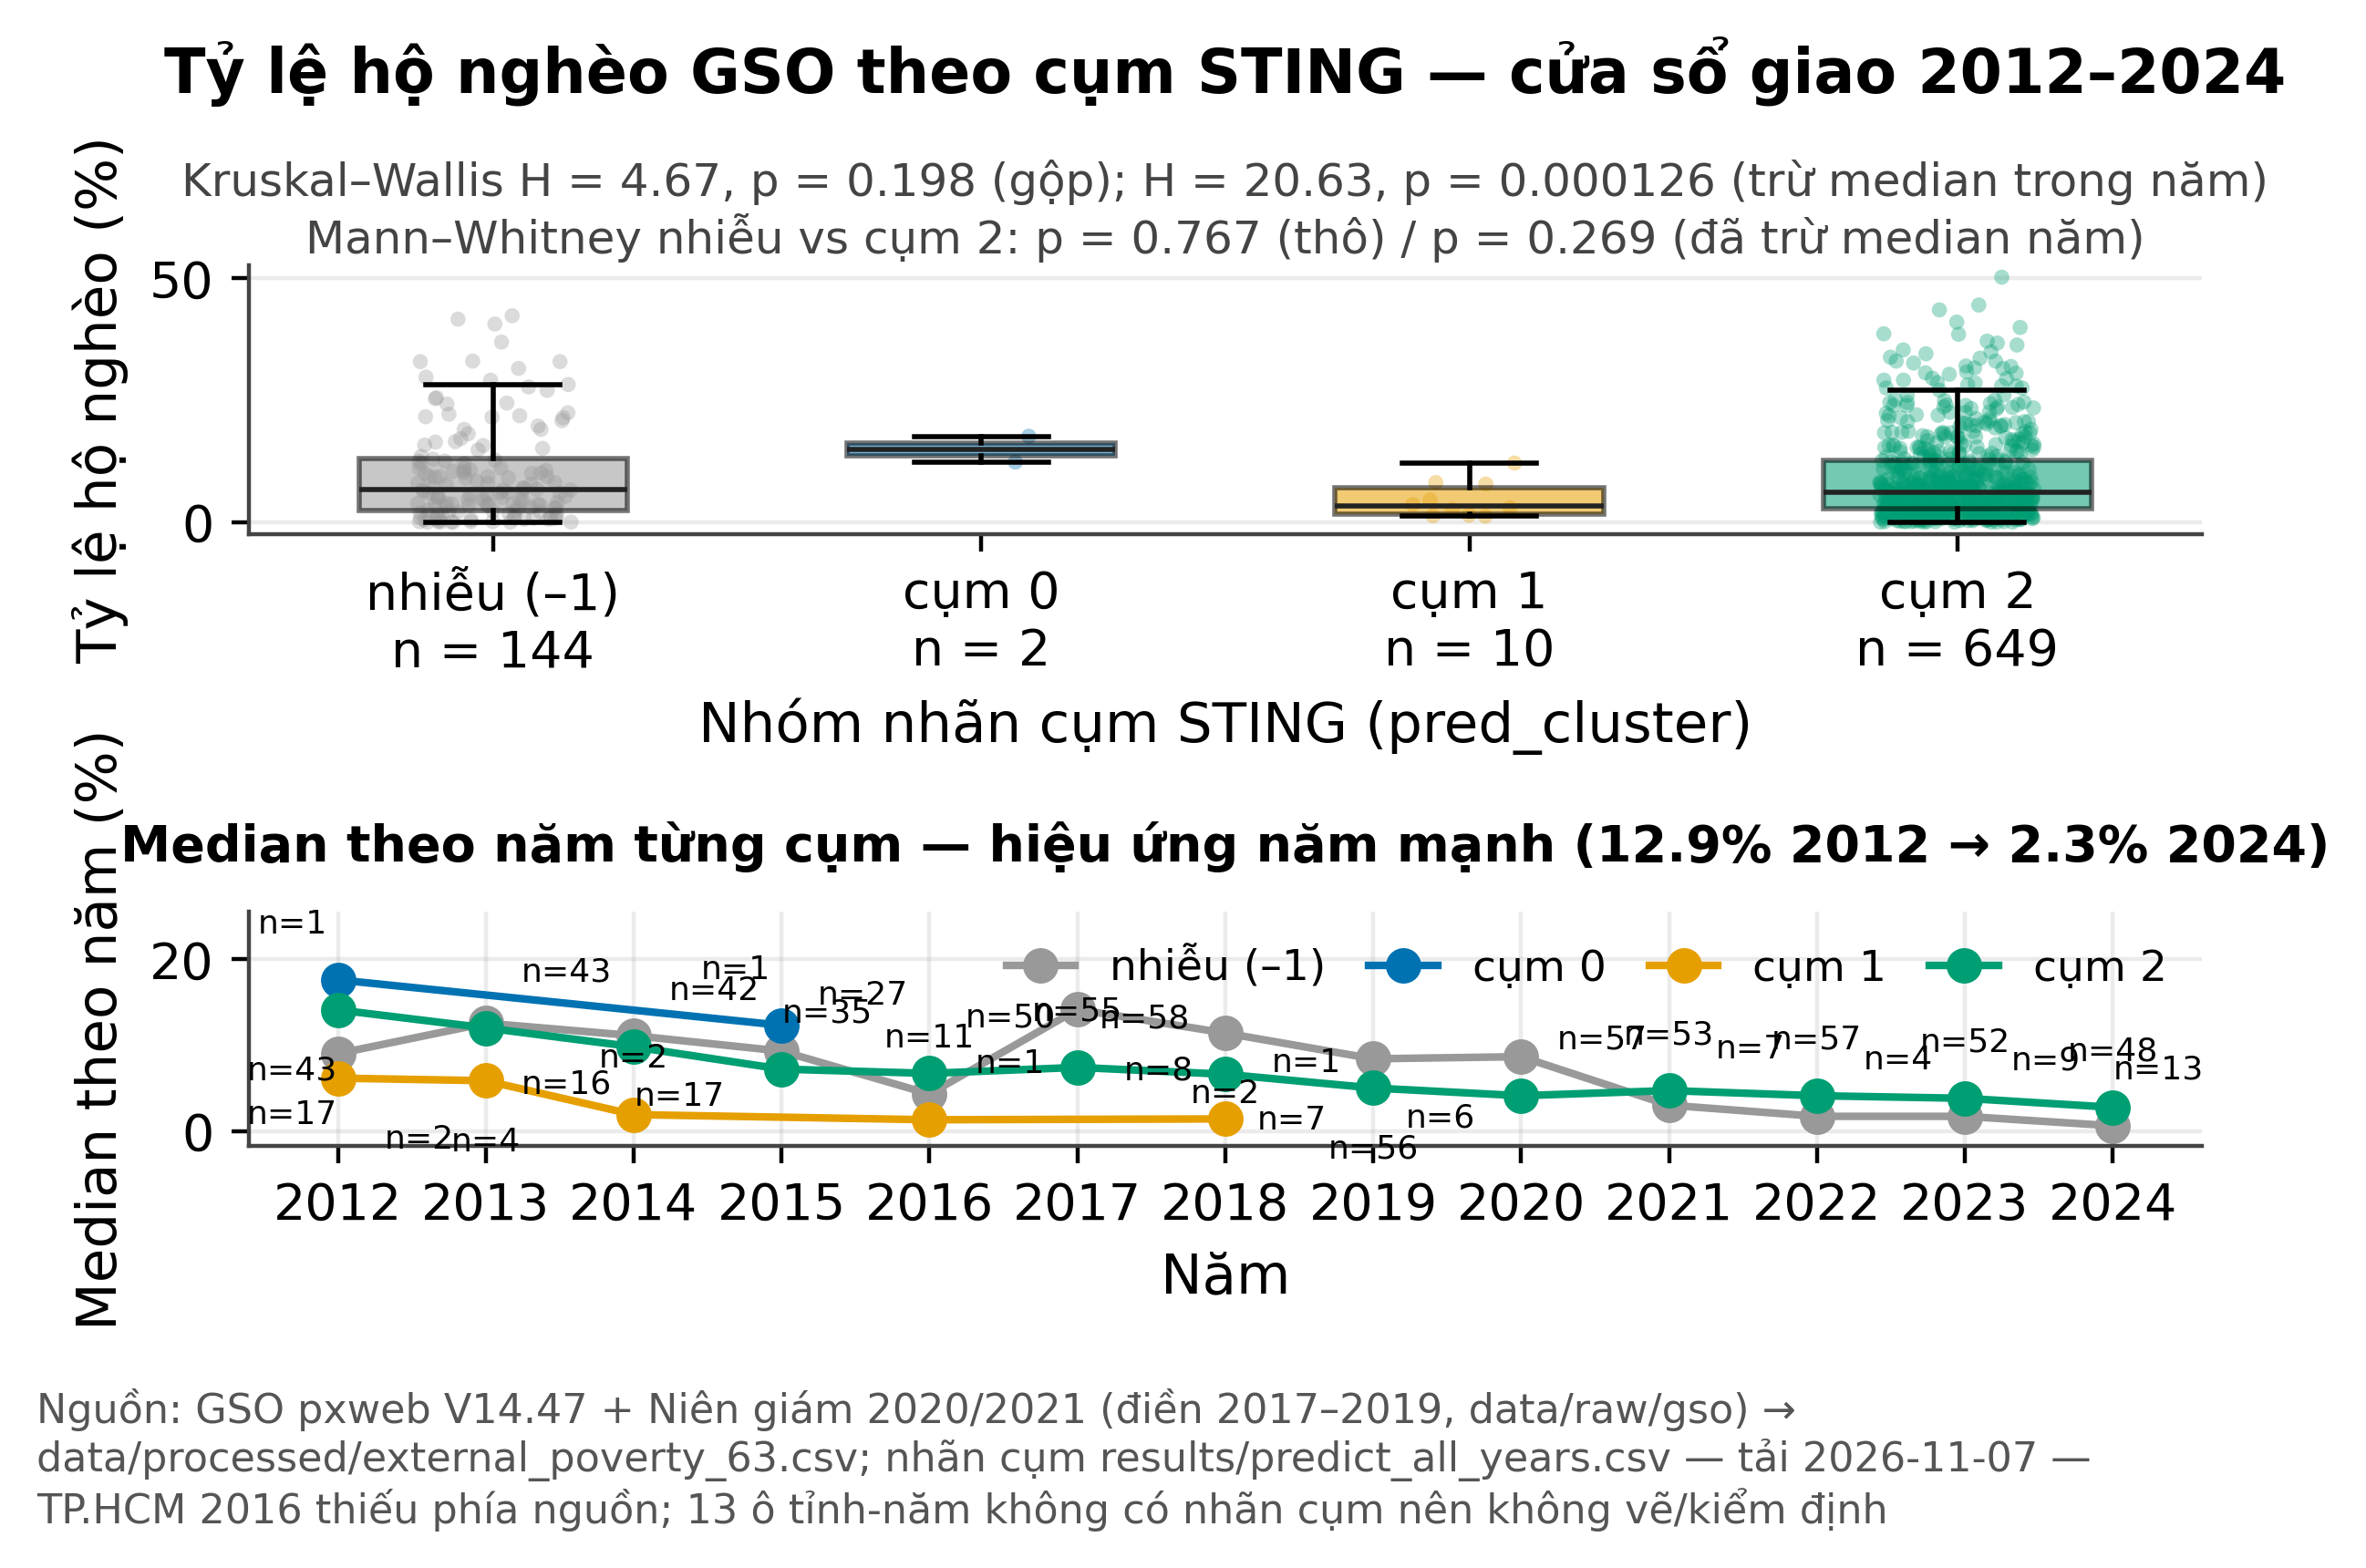

In [16]:
pov = pd.read_csv(ROOT / "results/poverty_validation.csv")

pooled_sections = ["poverty_pooled_raw", "poverty_pooled_demeaned", "test_mw_noise_vs_c2"]
pov_pool = pov[pov.section.isin(pooled_sections)].copy()
has_stats = pov_pool["mean"].notna() & pov_pool["mean"].astype(str).str.strip().ne("")
has_note = pov_pool["note"].notna() & pov_pool["note"].astype(str).str.strip().ne("")
show_md(pov_pool[has_stats].to_markdown(index=False))
print()
show_md(pov_pool[has_note][["section", "group", "n", "note"]].to_markdown(index=False))
print()

def _pov_note(section, group):
    return str(pov[(pov.section == section) & (pov.group == group)].iloc[0]["note"])

print("Gộp thô:                ", _pov_note("poverty_pooled_raw", "Kruskal–Wallis"))
print("Đã trừ median trong năm:", _pov_note("poverty_pooled_demeaned", "Kruskal–Wallis"))
for _, r in pov[pov.section == "test_mw_noise_vs_c2"].iterrows():
    print(f"{r['group']}: {r['note']}")
print()
_c0 = int(pov_pool[has_stats & pov_pool["group"].str.contains("cụm 0", regex=False)].iloc[0]["n"])
_c1 = int(pov_pool[has_stats & pov_pool["group"].str.contains("cụm 1", regex=False)].iloc[0]["n"])
print("Đọc trung thực: gộp thô KHÔNG đáng kể (nhiễm hiệu ứng năm); đã-trừ-median-năm đáng kể ở mức yếu.")
print(f"Cặp tương phản đáng tin duy nhất là nhiễu vs cụm 2 (cụm 0 n={_c0}, cụm 1 n={_c1} quá nhỏ):")
print("Các p-value Mann–Whitney ở trên không cho bằng chứng khác biệt ở mức 0.05;")
print("Đọc bảng PCI và nghèo GSO như phân tích bổ trợ theo nguồn độc lập.")

display(Image(filename=str(ROOT / "results/figs/external_poverty_by_cluster.png")))